# AQI v2 · New York City
## From a raw export to a quality-controlled, multi-standard, forecastable AQI

*Florian Grolleau · Air Quality Index Studies, version 2*

Version 1 (`AQIoverNY.ipynb`) computed a "CAQI" from `NYpollutants.csv`. This notebook
rebuilds the New York analysis from the ground up:

1. **Reading the data correctly.** The aqicn.org export does not contain concentrations
   but US EPA AQI sub-indices. Applying concentration breakpoints to them (v1) inflates
   pollution.
2. **Quality control against an independent network.** The EPA AirNow monitors inside the
   five boroughs reveal two silent sensor failures in the export; the regional network in
   turn bridges the gaps of the AirNow feed.
3. **A validated AQI engine.** `aqi2.indices` reproduces the AQI published by AirNow
   (exactly for ozone) and implements the 2024 PM2.5 revision, the European EAQI, the
   Canadian AQHI and the WHO 2021 guidelines.
4. **Exploration, trends and meteorological normalisation** (2014 to October 2026).
5. **Event attribution:** wildfire smoke, Independence Day fireworks and the COVID-19
   lockdown, with an in-time placebo test.
6. **Probabilistic forecasting** of the next three days with conformal prediction
   intervals, evaluated walk-forward over six years, and a live forecast.

In [1]:
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from aqi2 import data, features, forecasting as fc, indices as ix, spatial, viz  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
viz.set_theme()
RNG = np.random.default_rng(42)

## 0 · Data

| source | content | period |
|---|---|---|
| `NYpollutants.csv` (aqicn.org, v1 dataset) | daily PM2.5, O3, NO2, CO sub-indices for "New York" | 2014-01 to 2025-10 |
| EPA AirNow daily files (`scripts/fetch_airnow.py`) | 24 h PM2.5 and daily max 8 h O3 at every monitor of the tri-state region | 2014-01 to 2026-10 |
| NOAA GHCN-Daily and Global Hourly (`scripts/fetch_weather.py`) | temperature, wind, humidity, pressure, precipitation, haze flags at 7 stations | 2014-01 to 2026-10 |

AirNow data are real-time, not the final regulatory archive (EPA AQS), which is why they
need checks too. An automatic filter (`aqi2.qc`) removes physically impossible values and
stuck instruments (5 or more identical consecutive days). It matters: the Pfizer Lab
ozone monitor in the Bronx reported **0 ppb every day of 2014** and into 2015, which
would otherwise fake a strong upward ozone trend.

In [2]:
nyc = data.load_nyc_aqicn()
an, sites = data.load_airnow_daily()
wx = data.regional_weather(data.load_weather())

# AirNow is real-time data: stuck instruments are removed automatically (aqi2.qc)
from aqi2 import qc  # noqa: E402
qc_reports = {p: qc.qc_matrix(data.airnow_matrix(an, p, min_days=1, qc=False), **data.QC_RULES[p])[1]
              for p in ["pm25", "o3_8h"]}
for p, rep in qc_reports.items():
    print(f"{p}: {int(rep.flagged.sum())} station-days flagged out of {int(rep.valid.sum()):,} at flagged monitors")
display(qc_reports["o3_8h"].join(sites.site).head(5))

NYC_COUNTIES = ["BRONX", "KINGS", "NEW YORK", "QUEENS", "RICHMOND"]
nyc_sites = sites[(sites.state == "NY") & sites.county.str.upper().isin(NYC_COUNTIES)]
pm_st = data.airnow_matrix(an, "pm25", min_days=1)
pm_st = pm_st[pm_st.columns.intersection(nyc_sites.index)].clip(lower=0)
o3_st = data.airnow_matrix(an, "o3_8h", min_days=1)
o3_st = o3_st[o3_st.columns.intersection(nyc_sites.index)].clip(lower=0)
LAST_DAY = pm_st.index.max()

print(f"aqicn export: {nyc.index.min():%Y-%m-%d} to {nyc.index.max():%Y-%m-%d}, {len(nyc)} days")
print(f"AirNow NYC monitors: {pm_st.shape[1]} PM2.5, {o3_st.shape[1]} O3, last day {LAST_DAY:%Y-%m-%d}")
display(nyc_sites[["site", "county", "lat", "lon", "params"]].sort_values("county"))

pm25: 11 station-days flagged out of 6,182 at flagged monitors
o3_8h: 671 station-days flagged out of 125,570 at flagged monitors


,below floor,stuck runs,flagged,valid,site
full_aqsid,,,,,
840360050133,566,563,566,4389,Pfizer Lab
840421010004,22,7,22,4312,LABP
840090090027,6,0,6,4547,New Haven
840100031013,1,5,6,4428,BELLFNT2
840340210005,0,6,6,4548,Rider University


aqicn export: 2014-01-01 to 2025-10-13, 4304 days
AirNow NYC monitors: 14 PM2.5, 6 O3, last day 2026-10-23


,site,county,lat,lon,params
full_aqsid,,,,,
840360050133,Pfizer Lab,BRONX,40.868000,-73.878200,O3
840360050112,Bronx - IS74,BRONX,40.814701,-73.886703,PM2.5
840360050110,Bronx - IS52,BRONX,40.816101,-73.902199,"O3,PM2.5"
840360050080,Morrisania,BRONX,40.836700,-73.921400,PM2.5
840360470118,Bklyn - PS274,KINGS,40.694401,-73.928596,PM2.5
840360470052,Bklyn - PS 314,KINGS,40.641819,-74.018707,PM2.5
840360610115,Manhattan/IS143,NEW YORK,40.849200,-73.931900,PM2.5
840360610135,CCNY,NEW YORK,40.819700,-73.948100,"O3,PM2.5"
840360610134,Division Street,NEW YORK,40.714200,-73.995000,PM2.5


## 1 · What the numbers in `NYpollutants.csv` really are

aqicn.org publishes every pollutant **already converted to the US EPA AQI scale**
(0 to 500). Three facts in the file prove it:

* CO ranges from 1 to 10. As a concentration this would be 1 to 10 ppm every day, levels
  last seen in New York decades ago; as an AQI it is 0.1 to 1 ppm, typical today.
* O3 hits exactly **500**, the ceiling of the AQI scale, on 143 days.
* Converted back to concentrations with the inverse EPA breakpoints, the PM2.5 values
  track the AirNow monitors with r = 0.93 (section 2).

Version 1 treated these values as concentrations and fed them through home-made
breakpoints, so a PM2.5 AQI of 21 ("Good") became an index of 93. The overall AQI is
simply the **maximum of the sub-indices** and the dominant pollutant is the arg max.

In [3]:
display(nyc.describe().T[["count", "min", "50%", "max"]].rename(columns={"50%": "median"}))

,count,min,median,max
pm25,4249.0,4.0,38.0,247.0
o3,1992.0,1.0,30.0,500.0
no2,1959.0,1.0,11.0,44.0
co,1772.0,1.0,2.0,10.0


## 2 · Quality control with an independent network

Three checks compare the export with the EPA AirNow monitors of the five boroughs and
with the NOAA weather record.

**Dates.** Each column is cross-correlated, at lags of -2 to +2 days, with an
independent reference: the AirNow composite for PM2.5 and ozone, the observed wind speed
for NO2 and CO (wind disperses traffic pollutants the same day). PM2.5 peaks at lag 0;
ozone, NO2 and CO peak at **+1**: in the export, the gaseous pollutants are stamped one
day early. They are shifted back before any other use.

**Ozone plateau.** In 2019 the export reports an O3 AQI of 500 on 143 days, including
winter days. An ozone AQI of 200 requires an 8-hour average above 105 ppb; the NYC
monitors never measured more than 99 ppb in 13 years. Such values are flagged unless the
network confirms them.

**PM2.5 drift.** Converted back to concentrations, the export runs about 1.4 times the
network composite (it is built from hourly AQI readings, the network value is a 24-hour
mean), a stable ratio. From July 2021 to January 2022 the ratio jumps to 5 to 7: a
sensor drift that v1 read as the most polluted year of the decade. A robust detector
flags it: 31-day rolling median of the log ratio more than 0.5 above its long-run median.

In [4]:
def composite(m: pd.DataFrame, min_stations: int = 1) -> pd.Series:
    """Network composite by the anomaly method: robust to monitors joining or leaving."""
    anomalies = m - m.mean()
    out = anomalies.mean(axis=1) + m.mean().mean()
    return out.where(m.notna().sum(axis=1) >= min_stations)


pm_net = composite(pm_st).rename("pm25")       # ug/m3, 24 h
o3_net = composite(o3_st).rename("o3")         # ppb, daily max 8 h
o3_max_aqi = pd.Series(ix.epa_subindex(o3_st.max(axis=1), "o3_8h"), index=o3_st.index)

conc = ix.aqicn_to_concentration(nyc)
refs = {"pm25": pm_net, "o3": o3_net, "no2": wx.awnd, "co": wx.awnd}
lag_corr = pd.DataFrame({p: {lag: conc[p].where(nyc[p] < 200).shift(lag).corr(refs[p].reindex(nyc.index))
                             for lag in range(-2, 3)} for p in refs})
display(lag_corr.round(3).rename_axis("lag (days)"))
best_lag = lag_corr.abs().idxmax()
print("best lag per pollutant:", best_lag.to_dict())
nyc = nyc.copy()
for p in ["o3", "no2", "co"]:
    nyc[p] = nyc[p].shift(int(best_lag[p]))

aqicn_pm_conc = pd.Series(ix.epa_inverse(nyc.pm25, "pm25_2012"), index=nyc.index)
log_ratio = np.log(aqicn_pm_conc / pm_net.reindex(nyc.index)).replace([np.inf, -np.inf], np.nan)
roll = log_ratio.rolling(31, center=True, min_periods=10).median()
baseline = log_ratio.median()
flag_pm = (roll - baseline) > 0.5
flag_o3 = (nyc.o3 >= 200) & ~(o3_max_aqi.reindex(nyc.index) >= 151)

runs = flag_pm.astype(int).diff().fillna(0)
starts, ends = flag_pm.index[runs == 1], flag_pm.index[runs == -1]
print(f"stable ratio aqicn / network: {np.exp(baseline):.2f}")
print("PM2.5 drift periods:", [(f"{a:%Y-%m-%d}", f"{b:%Y-%m-%d}") for a, b in zip(starts, ends)])
print(f"flagged days: PM2.5 {flag_pm.sum()}, O3 {flag_o3.sum()}")

clean = nyc.copy()
clean.loc[flag_pm, "pm25"] = np.nan
clean.loc[flag_o3, "o3"] = np.nan
both = log_ratio.notna()
r_before = np.corrcoef(aqicn_pm_conc[both], pm_net.reindex(nyc.index)[both])[0, 1]
r_after = np.corrcoef(aqicn_pm_conc[both & ~flag_pm], pm_net.reindex(nyc.index)[both & ~flag_pm])[0, 1]
print(f"correlation export vs network: {r_before:.3f} before QC, {r_after:.3f} after QC")

,pm25,o3,no2,co
lag (days),,,,
-2,0.197,0.481,0.204,0.094
-1,0.401,0.545,0.164,0.040
0,0.633,0.673,-0.161,-0.261
1,0.364,0.921,-0.380,-0.380
2,0.174,0.631,0.035,0.012


best lag per pollutant: {'pm25': 0, 'o3': 1, 'no2': 1, 'co': 1}
stable ratio aqicn / network: 1.42
PM2.5 drift periods: [('2021-07-19', '2022-01-09')]
flagged days: PM2.5 174, O3 157
correlation export vs network: 0.689 before QC, 0.934 after QC


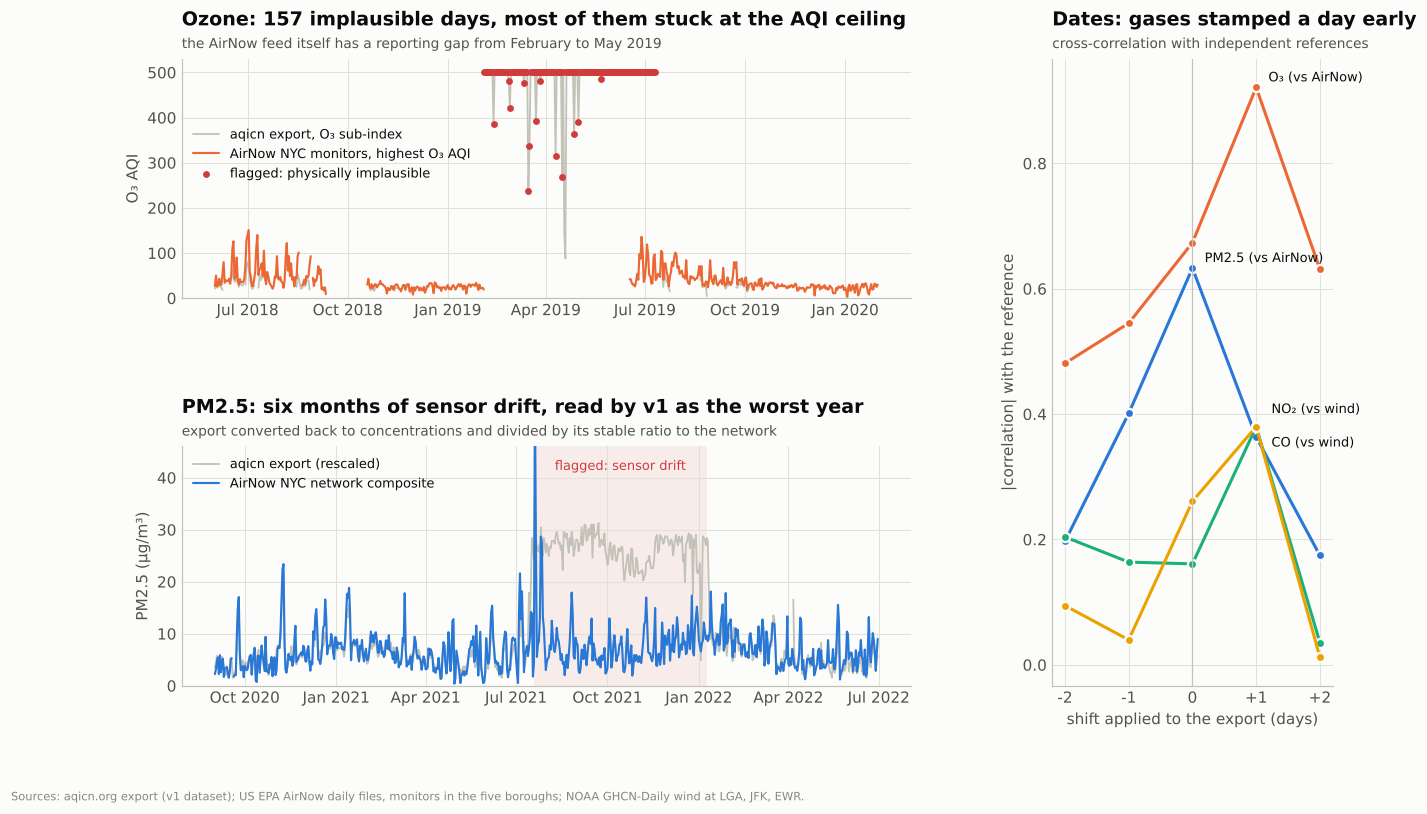

In [5]:
fig = plt.figure(figsize=(13.5, 7.4))
gs = fig.add_gridspec(2, 2, width_ratios=[2.6, 1], hspace=0.62, wspace=0.28)
axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])]
axl = fig.add_subplot(gs[:, 1])
label_offsets = {"pm25": (8, 4), "o3": (8, 4), "no2": (10, 9), "co": (10, -13)}
for p, color in [("pm25", viz.POLLUTANT_COLORS["pm25"]), ("o3", viz.POLLUTANT_COLORS["o3"]),
                 ("no2", viz.POLLUTANT_COLORS["no2"]), ("co", viz.POLLUTANT_COLORS["co"])]:
    v = lag_corr[p].abs()
    axl.plot(v.index, v, color=color, marker="o", ms=6, markeredgecolor=viz.SURFACE, markeredgewidth=1.5)
    axl.annotate(f"{viz.POLLUTANT_LABELS[p]} (vs {'AirNow' if p in ('pm25', 'o3') else 'wind'})",
                 xy=(v.idxmax(), v.max()), xytext=label_offsets[p], textcoords="offset points", fontsize=8.5,
                 color=viz.INK)
axl.axvline(0, color=viz.AXIS, lw=0.8)
axl.set_xticks(range(-2, 3), ["-2", "-1", "0", "+1", "+2"])
axl.set_xlabel("shift applied to the export (days)")
axl.set_ylabel("|correlation| with the reference")
viz.title(axl, "Dates: gases stamped a day early", "cross-correlation with independent references")
ax = axes[0]
seg = slice("2018-06-01", "2020-01-31")
ax.plot(nyc.o3[seg].index, nyc.o3[seg], color=viz.CONTEXT, lw=1.2, label="aqicn export, O₃ sub-index")
ax.plot(o3_max_aqi[seg].index, o3_max_aqi[seg], color=viz.POLLUTANT_COLORS["o3"], lw=1.4,
        label="AirNow NYC monitors, highest O₃ AQI")
bad = nyc.o3[seg][flag_o3[seg]]
ax.scatter(bad.index, bad, s=12, color="#d03b3b", zorder=3, label="flagged: physically implausible")
ax.set_ylabel("O₃ AQI")
ax.set_ylim(0, 530)
viz.title(ax, f"Ozone: {int(flag_o3.sum())} implausible days, most of them stuck at the AQI ceiling",
          "the AirNow feed itself has a reporting gap from February to May 2019")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.6), fontsize=8.5)
ax = axes[1]
seg = slice("2020-09-01", "2022-06-30")
ax.plot(aqicn_pm_conc[seg].index, aqicn_pm_conc[seg] / np.exp(baseline), color=viz.CONTEXT, lw=1.2,
        label="aqicn export (rescaled)")
ax.plot(pm_net[seg].index, pm_net[seg], color=viz.POLLUTANT_COLORS["pm25"], lw=1.4,
        label="AirNow NYC network composite")
for a, b in zip(starts, ends):
    ax.axvspan(a, b, color="#d03b3b", alpha=0.08, lw=0)
    ax.text(a + (b - a) / 2, 41.5, "flagged: sensor drift", ha="center", fontsize=8.5, color="#d03b3b")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_ylim(0, 46)
viz.title(ax, "PM2.5: six months of sensor drift, read by v1 as the worst year",
          "export converted back to concentrations and divided by its stable ratio to the network")
ax.legend(loc="upper left", fontsize=8.5)
for a in axes:
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
viz.source_note(fig, "Sources: aqicn.org export (v1 dataset); US EPA AirNow daily files, monitors in the five boroughs; "
                "NOAA GHCN-Daily wind at LGA, JFK, EWR.")
viz.save(fig, "01_quality_control")
plt.show()

### 2.1 · Bridging the gaps of the AirNow feed

The AirNow feed has holes too: no NYC PM2.5 or ozone was reported from February to May
2019, and only a few monitors in autumn 2018. The surrounding network (New Jersey,
Westchester, Long Island and Connecticut monitors within 80 km of Midtown) kept
reporting. A two-stage model reconstructs the NYC composite from it: a linear fit on the
regional composite, which extrapolates safely to smoke days, plus gradient-boosted
corrections from the individual regional monitors and the season. Validation holds out
whole months. Reconstructed days are flagged in the output file.

In [6]:
dist_mid = pd.Series(spatial.haversine_km(sites.lat, sites.lon, *spatial.NYC_CENTER), index=sites.index)


def regional_fill(param: str, target: pd.Series, radius_km: float = 80, n_folds: int = 5):
    M = data.airnow_matrix(an, param, min_days=1).clip(lower=0)
    reg_ids = [c for c in M.columns if c not in nyc_sites.index and dist_mid.get(c, 1e9) <= radius_km]
    X = M[reg_ids].set_axis([f"s{i}" for i in range(len(reg_ids))], axis=1)
    X["regional"] = composite(M[reg_ids])
    X = X.join(features.calendar_features(X.index)[["doy_sin", "doy_cos", "dow"]])
    df = X.join(target.rename("y")).dropna(subset=["y", "regional"])
    months = df.index.to_period("M")
    fold_of = dict(zip(months.unique(), RNG.integers(0, n_folds, months.nunique())))
    fold = np.array([fold_of[m] for m in months])

    def fit_predict(train, test):
        b = np.polyfit(train.regional, train.y, 1)
        resid = train.y - np.polyval(b, train.regional)
        gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, verbose=-1, n_jobs=4).fit(train.drop(columns="y"), resid)
        lin = np.polyval(b, test.regional)
        return lin, lin + gbm.predict(test.drop(columns="y", errors="ignore"))

    lin_cv, hyb_cv = np.zeros(len(df)), np.zeros(len(df))
    for k in range(n_folds):
        tr, te = fold != k, fold == k
        lin_cv[te], hyb_cv[te] = fit_predict(df[tr], df[te])
    cv = {name: fc.regression_scores(df.y, p) for name, p in [("linear", lin_cv), ("linear + boosting", hyb_cv)]}
    todo = X[target.reindex(X.index).isna() & X.regional.notna()]
    _, filled = fit_predict(df, todo)
    out = target.reindex(target.index.union(todo.index))
    out.loc[todo.index] = np.clip(filled, 0, None)
    return out, pd.Series(out.index.isin(todo.index), index=out.index), cv, len(reg_ids)


pm_net, pm_filled, cv_pm, n_pm = regional_fill("pm25", pm_net)
o3_net, o3_filled, cv_o3, n_o3 = regional_fill("o3_8h", o3_net)
cv_tab = pd.DataFrame({(p, m): v for p, cv in [("PM2.5", cv_pm), ("O3", cv_o3)] for m, v in cv.items()}).T
display(cv_tab[["MAE", "RMSE", "R2", "n"]].astype(float).round(3))
print(f"reconstructed days: PM2.5 {pm_filled.sum()} (from {n_pm} regional monitors), O3 {o3_filled.sum()} ({n_o3})")

MAE   RMSE     R2       n
PM2.5 linear             1.242  1.783  0.880  4480.0
      linear + boosting  0.771  1.266  0.939  4480.0
O3    linear             2.767  3.654  0.921  4459.0
      linear + boosting  1.770  2.413  0.966  4459.0

reconstructed days: PM2.5 199 (from 16 regional monitors), O3 220 (16)


### 2.2 · The AQI engine, checked against the official values

Since 2019 the AirNow files publish the AQI next to each concentration. Recomputing it
with `aqi2.indices` over the whole tri-state region:

In [7]:
v2rows = an[(an.fmt == "v2") & an.aqi.notna() & (an.aqi >= 0)]
checks = []
for param, table, period in [("o3_8h", "o3_8h", None), ("pm25", "pm25_2012", ("2018-01-01", "2024-05-05")),
                             ("pm25", "pm25", ("2024-05-06", "2100-01-01")), ("co", "co", None),
                             ("pm10", "pm10", None)]:
    d = v2rows[v2rows.param == param]
    if period:
        d = d[(d.date >= period[0]) & (d.date <= period[1])]
    calc = ix.epa_subindex(d.value.clip(lower=0), table)
    diff = calc - d.aqi.to_numpy()
    checks.append({"pollutant": param, "breakpoints": table, "station-days": len(d),
                   "exact match (%)": 100 * np.mean(diff == 0),
                   "within 1 point (%)": 100 * np.mean(np.abs(diff) <= 1)})
display(pd.DataFrame(checks).round(2))

,pollutant,breakpoints,station-days,exact match (%),within 1 point (%)
0,o3_8h,o3_8h,159138,100.00,100.00
1,pm25,pm25_2012,106072,82.95,99.95
2,pm25,pm25,54524,98.87,100.00
3,co,co,34310,67.88,99.99
4,pm10,pm10,26858,74.07,100.00


Ozone matches exactly. For PM2.5, CO and PM10 the residual differences are all of one
point and in the same direction: AirNow computes the index from unrounded concentrations
and then publishes the concentration rounded to one decimal. The table also dates the
switch to the new PM2.5 breakpoints in the AirNow feed: **early May 2024**.

### 2.3 · NYC AQI v2

From here on, the New York daily AQI is computed from the **network composites**
(PM2.5 24-hour mean, ozone daily maximum 8-hour mean) with the current EPA breakpoints.
The cleaned export provides NO2 (2018 onwards), which AirNow does not carry for NYC.
The result is saved to `data/processed/nyc_aqi_v2_daily.csv`.

In [8]:
d = pd.DataFrame({"pm25": pm_net, "o3": o3_net})
d["pm25_reconstructed"], d["o3_reconstructed"] = pm_filled.reindex(d.index), o3_filled.reindex(d.index)
d["no2"] = pd.Series(ix.epa_inverse(clean.no2, "no2"), index=clean.index).reindex(d.index)
sub = pd.DataFrame({"pm25": ix.epa_subindex(d.pm25, "pm25"), "o3": ix.epa_subindex(d.o3, "o3_8h")}, index=d.index)
ov = ix.overall_aqi(sub)
d["aqi_pm25"], d["aqi_o3"] = sub.pm25, sub.o3
d["aqi"], d["dominant"] = ov.aqi, ov.dominant
d["aqi_pm25_2012"] = ix.epa_subindex(d.pm25, "pm25_2012")
d["category"] = ix.epa_category_name(d.aqi, short=True)
nyc_v2 = d.loc["2014-01-01":LAST_DAY].copy()
out_dir = data.DATA / "processed"
out_dir.mkdir(exist_ok=True)
nyc_v2.round(3).to_csv(out_dir / "nyc_aqi_v2_daily.csv")
display(nyc_v2.tail(5))
display(nyc_v2.category.value_counts(normalize=True).mul(100).round(1).rename("% of days"))

,pm25,o3,pm25_reconstructed,o3_reconstructed,no2,aqi_pm25,aqi_o3,aqi,dominant,aqi_pm25_2012,category
date,,,,,,,,,,,
2026-10-19,6.418544,26.996233,False,False,NaN,36.0,24.0,36.0,pm25,27.0,Good
2026-10-20,3.940702,35.850524,False,False,NaN,22.0,32.0,32.0,o3,16.0,Good
2026-10-21,3.370702,23.725176,False,False,NaN,18.0,21.0,21.0,o3,14.0,Good
2026-10-22,4.300702,34.350524,False,False,NaN,24.0,31.0,31.0,o3,18.0,Good
2026-10-23,4.920702,29.523076,False,False,NaN,27.0,27.0,27.0,pm25,20.0,Good


category
Good              72.0
Moderate          26.8
USG                1.0
Unhealthy          0.1
Very Unhealthy     0.0
Name: % of days, dtype: float64

### 2.4 · What changes from v1

On the days v1 used (all four pollutants present, and none flagged by the QC), the share
of days in each EPA category according to v1's reading and to the correct one:

,Good,Moderate,USG,Unhealthy,Very Unhealthy,Hazardous
v1 (misread),1.0,19.2,32.0,14.6,12.5,20.8
v2 (correct),78.0,21.3,0.5,0.1,0.1,0.0


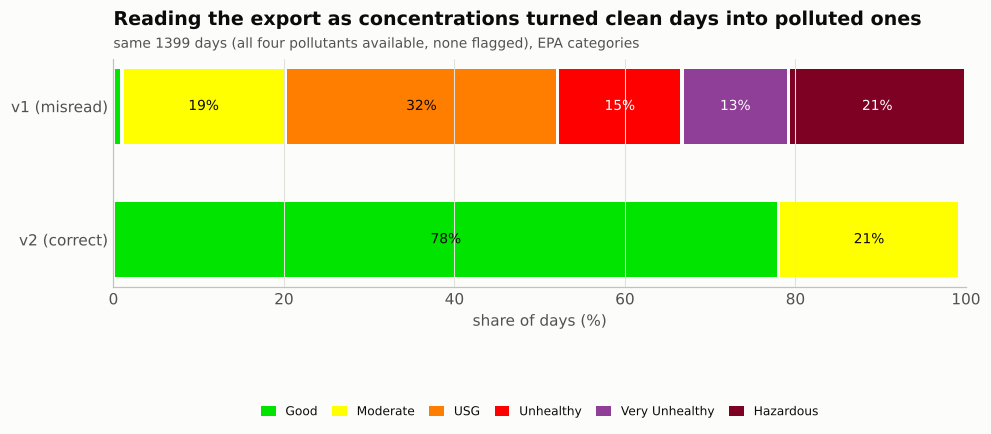

In [9]:
V1_BREAKPOINTS = {  # copied from AQIoverNY.ipynb (v1)
    "pm25": [(0, 11, 0, 50), (12, 23, 51, 100), (24, 35, 101, 150), (36, 41, 151, 200),
             (42, 47, 201, 300), (48, 53, 301, 400), (54, 70, 401, 500)],
    "o3": [(0, 40, 0, 50), (41, 80, 51, 100), (81, 180, 101, 150), (181, 240, 151, 200),
           (241, 300, 201, 300), (301, 400, 301, 400), (401, 500, 401, 500)],
    "no2": [(0, 67, 0, 50), (68, 134, 51, 100), (135, 200, 101, 150), (201, 267, 151, 200),
            (268, 334, 201, 300), (335, 400, 301, 400), (401, 500, 401, 500)],
    "co": [(0, 1.0, 0, 50), (1.1, 2.0, 51, 100), (2.1, 3.0, 101, 150), (3.1, 4.0, 151, 200),
           (4.1, 5.0, 201, 300), (5.1, 6.0, 301, 400), (6.1, 10.0, 401, 500)],
}


def v1_subindex(x, pollutant):
    for lo, hi, ilo, ihi in V1_BREAKPOINTS[pollutant]:
        if lo <= x <= hi:
            return (ihi - ilo) / (hi - lo) * (x - lo) + ilo
    return np.nan


v1 = nyc.dropna()
v1 = v1[~flag_pm.reindex(v1.index) & ~flag_o3.reindex(v1.index)]
v1_index = pd.concat({p: v1[p].map(lambda x, p=p: v1_subindex(x, p)) for p in V1_BREAKPOINTS}, axis=1).max(axis=1)
v2_index = ix.overall_aqi(v1[["pm25", "o3", "no2", "co"]])["aqi"]
cmp = pd.DataFrame({"v1 (misread)": ix.epa_category(v1_index), "v2 (correct)": ix.epa_category(v2_index)},
                   index=v1.index)
share = cmp.apply(lambda s: s.value_counts(normalize=True)).reindex(range(6)).fillna(0) * 100
share.index = ix.EPA_SHORT
display(share.round(1).T)

fig, ax = plt.subplots(figsize=(10, 2.7))
for col, yy in {"v1 (misread)": 1, "v2 (correct)": 0}.items():
    left = 0
    for cat in ix.EPA_CATEGORIES:
        w = share.loc[cat.short, col]
        if w <= 0:
            continue
        ax.barh(yy, max(w - 0.4, 0.1), left=left + 0.2, height=0.56, color=cat.color, lw=0)
        if w > 6:
            dark = cat.short in ("Good", "Moderate", "USG")
            ax.text(left + w / 2, yy, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                    color=viz.INK if dark else "white")
        left += w
ax.set_yticks([1, 0], ["v1 (misread)", "v2 (correct)"])
ax.set_xlim(0, 100)
ax.set_xlabel("share of days (%)")
ax.grid(axis="y", visible=False)
viz.title(ax, "Reading the export as concentrations turned clean days into polluted ones",
          f"same {len(v1)} days (all four pollutants available, none flagged), EPA categories")
viz.aqi_legend(ax, bbox=(0.5, -0.62))
viz.save(fig, "01_v1_vs_v2_reading")
plt.show()

## 3 · Same air, different verdicts

The AQI is a reporting convention. Applying several of them to the same 13 years of New
York air shows how much the verdict depends on the rulebook.

* **EPA, 2012 breakpoints** (in force until May 2024) versus **EPA, 2024**: the PM2.5
  "Good" ceiling went from 12.0 to 9.0 ug/m3.
* **European EAQI** (EEA), evaluated on daily values (24 h PM2.5, maximum 8 h ozone
  converted to ug/m3) as an approximation of its hourly definition.
* **WHO 2021 guideline**: 15 ug/m3 for 24 h PM2.5, a health benchmark rather than an
  index, shown as days per year above the line.

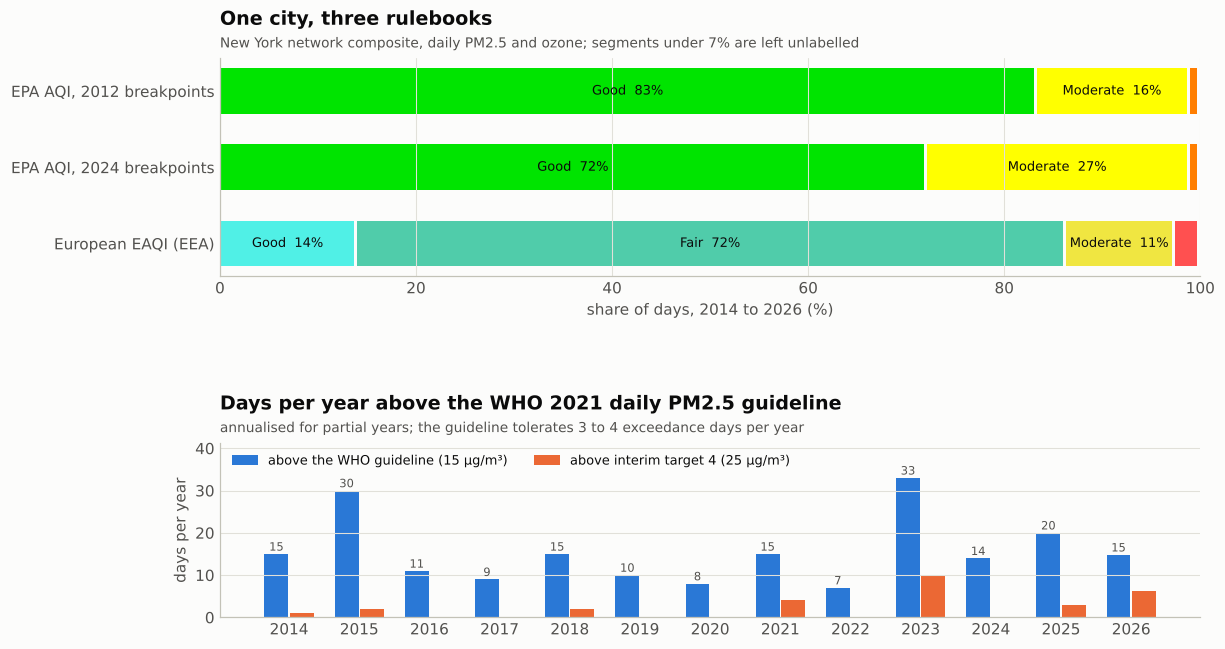

In [10]:
cat_12 = ix.epa_category(np.fmax(nyc_v2.aqi_pm25_2012, nyc_v2.aqi_o3))
cat_24 = ix.epa_category(nyc_v2.aqi)
eaqi = np.maximum(ix.eaqi_level(nyc_v2.pm25, "pm25"), ix.eaqi_level(ix.ppb_to_ugm3(nyc_v2.o3, "o3"), "o3"))
valid = nyc_v2.aqi.notna().to_numpy()
shares = {
    "EPA AQI, 2012 breakpoints": (pd.Series(cat_12[valid]).value_counts(normalize=True), ix.EPA_SHORT, ix.EPA_COLORS),
    "EPA AQI, 2024 breakpoints": (pd.Series(cat_24[valid]).value_counts(normalize=True), ix.EPA_SHORT, ix.EPA_COLORS),
    "European EAQI (EEA)": (pd.Series(eaqi[valid]).value_counts(normalize=True), ix.EAQI_LEVELS, ix.EAQI_COLORS),
}
LIGHT_FILLS = {"#00E400", "#FFFF00", "#FF7E00", "#50F0E6", "#50CCAA", "#F0E641"}
who = (nyc_v2.pm25 > ix.who_guideline("pm25", "24h")).groupby(nyc_v2.index.year).sum()
who_it4 = (nyc_v2.pm25 > ix.WHO_AQG_2021["pm25"]["24h"][1][3]).groupby(nyc_v2.index.year).sum()
n_days = nyc_v2.pm25.notna().groupby(nyc_v2.index.year).sum()

fig = plt.figure(figsize=(11.5, 6.6))
gs = fig.add_gridspec(2, 1, height_ratios=[1.25, 1], hspace=0.85)
ax = fig.add_subplot(gs[0])
for row, (name, (s, labels, colors)) in enumerate(shares.items()):
    left = 0
    for k in range(len(labels)):
        w = 100 * s.get(k, 0)
        if w <= 0:
            continue
        ax.barh(2 - row, max(w - 0.3, 0.1), left=left + 0.15, height=0.6, color=colors[k], lw=0)
        if w > 7:
            ax.text(left + w / 2, 2 - row, f"{labels[k]}  {w:.0f}%", ha="center", va="center", fontsize=8.5,
                    color=viz.INK if colors[k] in LIGHT_FILLS else "white")
        left += w
ax.set_yticks([2, 1, 0], list(shares))
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of days, 2014 to 2026 (%)")
viz.title(ax, "One city, three rulebooks",
          "New York network composite, daily PM2.5 and ozone; segments under 7% are left unlabelled")
ax2 = fig.add_subplot(gs[1])
yrs = who.index.to_numpy()
ann_who, ann_it4 = who / n_days * 365, who_it4 / n_days * 365
ax2.bar(yrs - 0.18, ann_who, width=0.34, color=viz.SERIES[0], label="above the WHO guideline (15 µg/m³)")
ax2.bar(yrs + 0.18, ann_it4, width=0.34, color=viz.SERIES[1], label="above interim target 4 (25 µg/m³)")
for x_, v_ in zip(yrs, ann_who):
    ax2.text(x_ - 0.18, v_ + 0.8, f"{v_:.0f}", ha="center", fontsize=7.5, color=viz.INK_2)
ax2.set_xticks(yrs)
ax2.set_ylabel("days per year")
ax2.set_ylim(0, ann_who.max() * 1.25)
viz.title(ax2, "Days per year above the WHO 2021 daily PM2.5 guideline",
          "annualised for partial years; the guideline tolerates 3 to 4 exceedance days per year")
ax2.legend(loc="upper left", ncol=2, fontsize=8.5)
ax2.grid(axis="x", visible=False)
viz.save(fig, "01_standards_comparison")
plt.show()

**Additive versus "worst pollutant wins".** The AQI reports only the dominant pollutant.
Canada's AQHI adds the risks of NO2, O3 and PM2.5 instead. On the days where all three
are available (NO2 from the cleaned export), how often are two or more pollutants
elevated at once, a situation the AQI cannot express?

In [11]:
tri = nyc_v2.dropna(subset=["pm25", "o3", "no2"]).copy()
tri["aqhi"] = ix.aqhi(tri.no2, tri.o3, tri.pm25)
sub_no2 = ix.epa_subindex(tri.no2, "no2")
n_elevated = pd.DataFrame({"pm": tri.aqi_pm25 > 50, "o3": tri.aqi_o3 > 50, "no2": sub_no2 > 50}).sum(axis=1)
print(f"days with PM2.5, O3 and NO2: {len(tri)}")
print(f"days with two or more pollutants above 'Good' at once: {100 * (n_elevated >= 2).mean():.1f}%")
print(f"Spearman correlation AQI vs AQHI: {stats.spearmanr(tri.aqi, tri.aqhi).statistic:.2f}")
display(pd.crosstab(pd.Series(ix.epa_category_name(tri.aqi, short=True), name="EPA AQI category"),
                    pd.Series(np.array(ix.AQHI_LEVELS)[ix.aqhi_level(tri.aqhi)], name="AQHI band")))

days with PM2.5, O3 and NO2: 1959
days with two or more pollutants above 'Good' at once: 6.0%
Spearman correlation AQI vs AQHI: 0.79


AQHI band,High risk,Low risk,Moderate risk
EPA AQI category,,,
Good,0,1051,383
Moderate,0,75,423
USG,2,0,21
Unhealthy,3,0,0
Very Unhealthy,1,0,0


## 4 · Thirteen years at a glance

Every day since January 2014, coloured by its AQI category (2024 breakpoints). Dots mark
days reconstructed from the regional network (section 2.1).

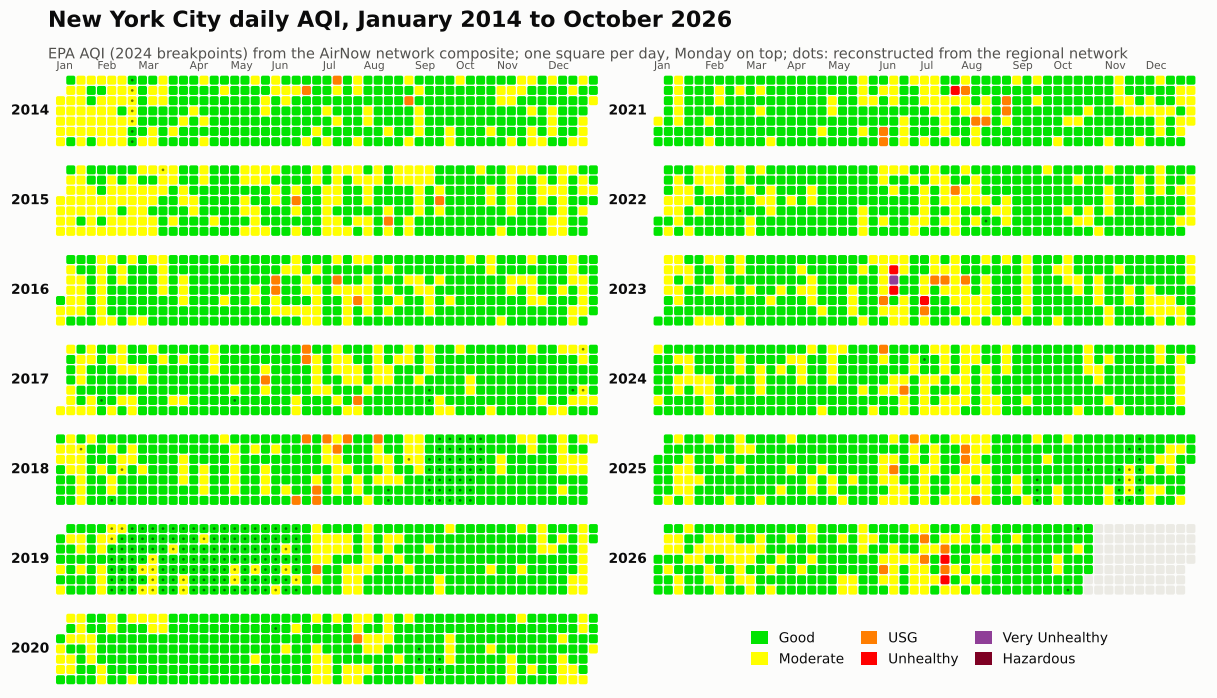

In [12]:
years = list(range(2014, LAST_DAY.year + 1))
n_rows = int(np.ceil(len(years) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(13.5, 0.95 * n_rows + 0.6), gridspec_kw={"wspace": 0.08, "hspace": 0.18})
recon = nyc_v2.pm25_reconstructed.astype(bool) | nyc_v2.o3_reconstructed.astype(bool)
for k, yr in enumerate(years):
    ax = axes[k % n_rows, k // n_rows]
    viz.calendar_heatmap(ax, nyc_v2.aqi, yr, show_months=(k % n_rows == 0), marked=recon)
for k in range(len(years), 2 * n_rows):
    axes[k % n_rows, k // n_rows].axis("off")
viz.fig_title(fig, "New York City daily AQI, January 2014 to October 2026",
              "EPA AQI (2024 breakpoints) from the AirNow network composite; one square per day, Monday on top; "
              "dots: reconstructed from the regional network", x=0.12)
viz.aqi_legend(axes[-1, 1], loc="center", bbox=(0.5, 0.5), ncol=3, fontsize=9)
viz.save(fig, "01_calendar_aqi")
plt.show()

### 4.1 · Seasons, weekdays and the dominant pollutant

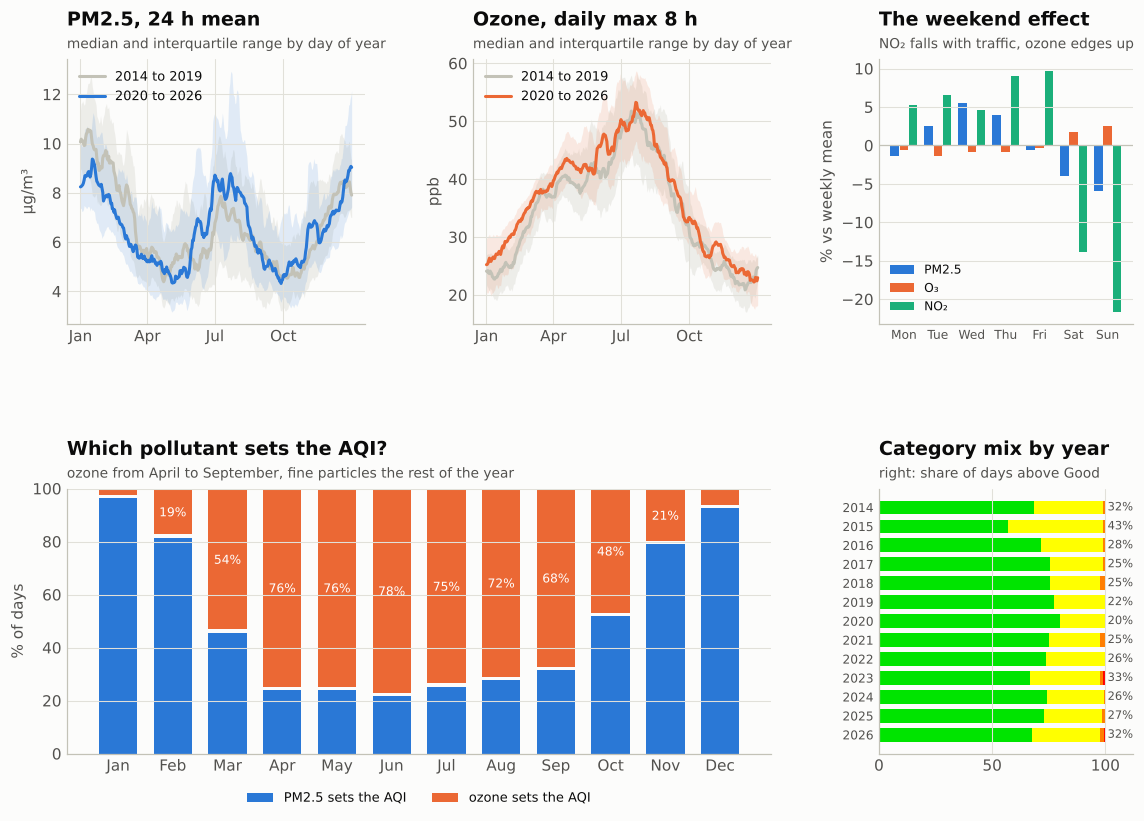

In [13]:
fig = plt.figure(figsize=(12.5, 8.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.85], hspace=0.62, wspace=0.38)
periods = {"2014 to 2019": ("2014", "2019"), "2020 to 2026": ("2020", "2026")}
for col, (var, unit, label) in enumerate([("pm25", "µg/m³", "PM2.5, 24 h mean"),
                                           ("o3", "ppb", "Ozone, daily max 8 h")]):
    ax = fig.add_subplot(gs[0, col])
    for k, (pname, (a, b)) in enumerate(periods.items()):
        s = nyc_v2[var].loc[a:b]
        g = s.groupby(s.index.dayofyear)
        med = g.median().rolling(15, center=True, min_periods=1).mean()
        q1 = g.quantile(0.25).rolling(15, center=True, min_periods=1).mean()
        q3 = g.quantile(0.75).rolling(15, center=True, min_periods=1).mean()
        color = viz.POLLUTANT_COLORS[var] if k == 1 else viz.CONTEXT
        ax.fill_between(med.index, q1, q3, color=color, alpha=0.13 if k == 1 else 0.25, lw=0)
        ax.plot(med.index, med, color=color, lw=2, label=pname)
    ax.set_xticks([1, 91, 182, 274], ["Jan", "Apr", "Jul", "Oct"])
    ax.set_ylabel(unit)
    viz.title(ax, label, "median and interquartile range by day of year")
    ax.legend(loc="upper left", fontsize=8.5)
ax = fig.add_subplot(gs[0, 2])
wk = pd.DataFrame({"PM2.5": nyc_v2.pm25, "O₃": nyc_v2.o3, "NO₂": nyc_v2.no2})
anom = wk.groupby(wk.index.dayofweek).mean() / wk.mean() * 100 - 100
x = np.arange(7)
for k, (col, color) in enumerate(zip(anom.columns, [viz.POLLUTANT_COLORS[p] for p in ("pm25", "o3", "no2")])):
    ax.bar(x + (k - 1) * 0.27, anom[col], width=0.25, color=color, label=col)
ax.axhline(0, color=viz.AXIS, lw=0.8)
ax.set_xticks(x, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
ax.set_ylabel("% vs weekly mean")
viz.title(ax, "The weekend effect", "NO₂ falls with traffic, ozone edges up")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="x", visible=False)

ax = fig.add_subplot(gs[1, 0:2])
dom = nyc_v2.dropna(subset=["aqi"])
by_month = pd.crosstab(dom.index.month, dom.dominant, normalize="index") * 100
mx = np.arange(1, 13)
ax.bar(mx, by_month["pm25"], width=0.7, color=viz.POLLUTANT_COLORS["pm25"], label="PM2.5 sets the AQI", lw=0)
ax.bar(mx, by_month["o3"] - 1.2, bottom=by_month["pm25"] + 1.2, width=0.7, color=viz.POLLUTANT_COLORS["o3"],
       label="ozone sets the AQI", lw=0)
for m_, v_ in zip(mx, by_month["o3"]):
    if v_ > 12:
        ax.text(m_, 100 - v_ / 2, f"{v_:.0f}%", ha="center", va="center", fontsize=8, color="white")
ax.set_xticks(mx, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(0, 100)
ax.set_ylabel("% of days")
viz.title(ax, "Which pollutant sets the AQI?", "ozone from April to September, fine particles the rest of the year")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.1), fontsize=8.5)
ax.grid(axis="x", visible=False)

ax = fig.add_subplot(gs[1, 2])
cat_year = pd.crosstab(nyc_v2.index.year, nyc_v2.category, normalize="index") * 100
bottom = np.zeros(len(cat_year))
for cat in ix.EPA_CATEGORIES[:4]:
    if cat.short in cat_year:
        v = cat_year[cat.short].to_numpy()
        ax.barh(cat_year.index, v, left=bottom, height=0.72, color=cat.color, lw=0, label=cat.short)
        bottom += v
for y_, v_ in zip(cat_year.index, 100 - cat_year.get("Good", 0)):
    ax.text(101, y_, f"{v_:.0f}%", va="center", fontsize=7.5, color=viz.INK_2)
ax.invert_yaxis()
ax.set_yticks(cat_year.index)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlim(0, 112)
ax.set_xticks([0, 50, 100])
ax.grid(axis="y", visible=False)
viz.title(ax, "Category mix by year", "right: share of days above Good")
viz.save(fig, "01_seasonality")
plt.show()

## 5 · Trends, with and without the weather

Air quality responds to emissions **and** to meteorology: a hot, stagnant summer raises
ozone whatever the emissions. To isolate the emission signal we use **meteorological
normalisation** (Grange & Carslaw, 2019): a gradient-boosting model learns each pollutant
as a function of weather, season, weekday and a time variable; then, for every day, all
inputs except time are replaced 300 times by values drawn from random days of the record
and the predictions are averaged. What remains is the trend the weather cannot explain.

Trends are summarised with the Theil-Sen slope and the Mann-Kendall test on monthly
means (deseasonalised by STL for the observed series), both robust to outliers such as
the June 2023 smoke.

In [14]:
from statsmodels.tsa.seasonal import STL  # noqa: E402

WX_DEWEATHER = ["t_mean", "t_max", "t_min", "td_mean", "rh_mean", "slp_mean", "ws_mean", "u_mean", "v_mean",
                "calm_frac", "prcp", "snwd", "slp_tendency", "t_aft", "ws_aft"]
dw_end = wx[WX_DEWEATHER].dropna().index.max()
base = nyc_v2.loc[:dw_end, ["pm25", "o3"]].join(wx[WX_DEWEATHER])
cal = features.calendar_features(base.index)[["doy_sin", "doy_cos", "dow", "holiday", "fireworks", "year_frac"]]
base = base.join(cal)
RESAMPLED = WX_DEWEATHER + ["doy_sin", "doy_cos", "dow", "holiday", "fireworks"]
FEATS = RESAMPLED + ["year_frac"]


def deweather(target: str, n_draws: int = 300):
    df = base.dropna(subset=WX_DEWEATHER + [target])
    m = lgb.LGBMRegressor(n_estimators=700, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, verbose=-1, n_jobs=4).fit(df[FEATS], df[target])
    pool = df[RESAMPLED].to_numpy()
    out = np.empty(len(df))
    for start in range(0, len(df), 500):
        stop = min(start + 500, len(df))
        idx = RNG.integers(0, len(df), size=(stop - start) * n_draws)
        X = np.empty((len(idx), len(FEATS)))
        X[:, :len(RESAMPLED)] = pool[idx]
        X[:, -1] = np.repeat(df.year_frac.to_numpy()[start:stop], n_draws)
        out[start:stop] = m.predict(pd.DataFrame(X, columns=FEATS)).reshape(stop - start, n_draws).mean(axis=1)
    return pd.Series(out, index=df.index, name=f"{target}_normalised"), df[target]


def trend_stats(s: pd.Series, deseasonalise: bool):
    mon = s.resample("MS").mean().dropna()
    if deseasonalise:
        mon = mon - STL(mon, period=12, robust=True).fit().seasonal
    t = (mon.index.year + (mon.index.month - 0.5) / 12).to_numpy()
    slope, intercept, lo, hi = stats.theilslopes(mon.to_numpy(), t)
    p = stats.kendalltau(t, mon.to_numpy()).pvalue
    return {"slope": slope, "lo": lo, "hi": hi, "p": p, "mean": mon.mean(), "intercept": intercept}


normalised, trend_rows = {}, []
for target in ["pm25", "o3"]:
    norm_s, obs_s = deweather(target)
    normalised[target] = (norm_s, obs_s)
    for kind, s, ds in [("observed", obs_s, True), ("weather-normalised", norm_s, False)]:
        t = trend_stats(s, ds)
        trend_rows.append({"pollutant": target, "series": kind, "slope per year": t["slope"],
                           "95% CI": f"[{t['lo']:.2f}, {t['hi']:.2f}]", "% per year": 100 * t["slope"] / t["mean"],
                           "Mann-Kendall p": t["p"]})
trends = pd.DataFrame(trend_rows)
display(trends.round(3))

,pollutant,series,slope per year,95% CI,% per year,Mann-Kendall p
0,pm25,observed,-0.006,"[-0.05, 0.03]",-0.090,0.729
1,pm25,weather-normalised,0.013,"[-0.03, 0.04]",0.183,0.616
2,o3,observed,0.362,"[0.27, 0.45]",1.011,0.000
3,o3,weather-normalised,0.252,"[0.20, 0.30]",0.699,0.000


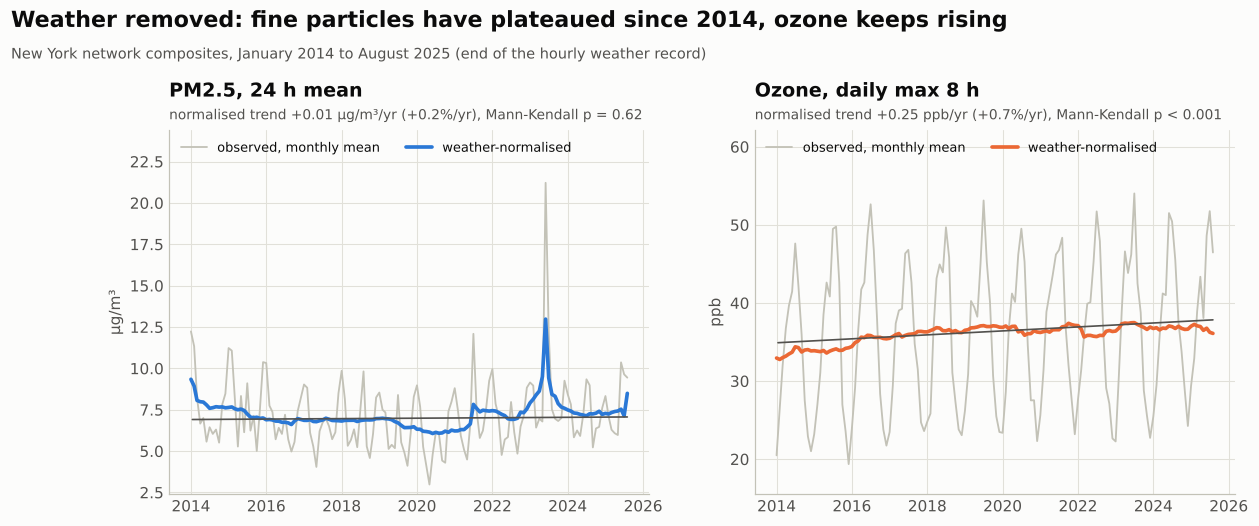

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharex=True, gridspec_kw={"wspace": 0.22})
for ax, target, unit in zip(axes, ["pm25", "o3"], ["µg/m³", "ppb"]):
    norm_s, obs_s = normalised[target]
    obs_m = obs_s.resample("MS").mean()
    nrm_m = norm_s.resample("MS").mean()
    color = viz.POLLUTANT_COLORS[target]
    ax.plot(obs_m.index, obs_m, color=viz.CONTEXT, lw=1.2, label="observed, monthly mean")
    ax.plot(nrm_m.index, nrm_m, color=color, lw=2.4, label="weather-normalised")
    t = trend_stats(norm_s, False)
    tt = np.array([obs_m.index[0].year + 0.04, obs_m.index[-1].year + obs_m.index[-1].month / 12])
    ax.plot([pd.Timestamp(f"{obs_m.index[0].year}-01-15"), obs_m.index[-1]], t["intercept"] + t["slope"] * tt,
            color=viz.INK_2, lw=1.1)
    p_txt = "p < 0.001" if t["p"] < 0.001 else f"p = {t['p']:.2f}"
    name = "PM2.5, 24 h mean" if target == "pm25" else "Ozone, daily max 8 h"
    viz.title(ax, name, f"normalised trend {t['slope']:+.2f} {unit}/yr ({100 * t['slope'] / t['mean']:+.1f}%/yr), "
              f"Mann-Kendall {p_txt}")
    ax.set_ylabel(unit)
    ax.legend(loc="upper left", fontsize=8.5, ncol=2)
    ax.set_ylim(obs_m.min() * 0.8, obs_m.max() * 1.15)
viz.fig_title(fig, "Weather removed: fine particles have plateaued since 2014, ozone keeps rising",
              f"New York network composites, January 2014 to {dw_end:%B %Y} (end of the hourly weather record)")
viz.save(fig, "01_trends_deweathered")
plt.show()

A rising ozone trend in the urban core alongside falling NOx emissions is a known
signature of **reduced titration**: less NO is available to destroy ozone locally, so
urban ozone drifts up towards suburban levels. The geospatial notebook (03) shows the
corresponding spatial pattern.

## 6 · Events

### 6.1 · Smoke

The ten most polluted days of the record. The haze column is the NOAA "smoke or haze"
weather type (WT08) reported at Central Park or any of the three airports.

,pm25,aqi,category,dominant,haze reported
date,,,,,
2023-06-07,154.2,229.0,Very Unhealthy,pm25,yes
2026-07-16,87.8,174.0,Unhealthy,pm25,yes
2023-06-08,76.8,166.0,Unhealthy,pm25,yes
2023-06-06,71.1,162.0,Unhealthy,pm25,yes
2023-06-30,57.8,153.0,Unhealthy,pm25,yes
2026-07-18,57.0,152.0,Unhealthy,pm25,yes
2021-07-20,56.8,152.0,Unhealthy,pm25,yes
2026-07-17,48.7,134.0,USG,pm25,yes
2026-07-15,46.5,128.0,USG,pm25,yes


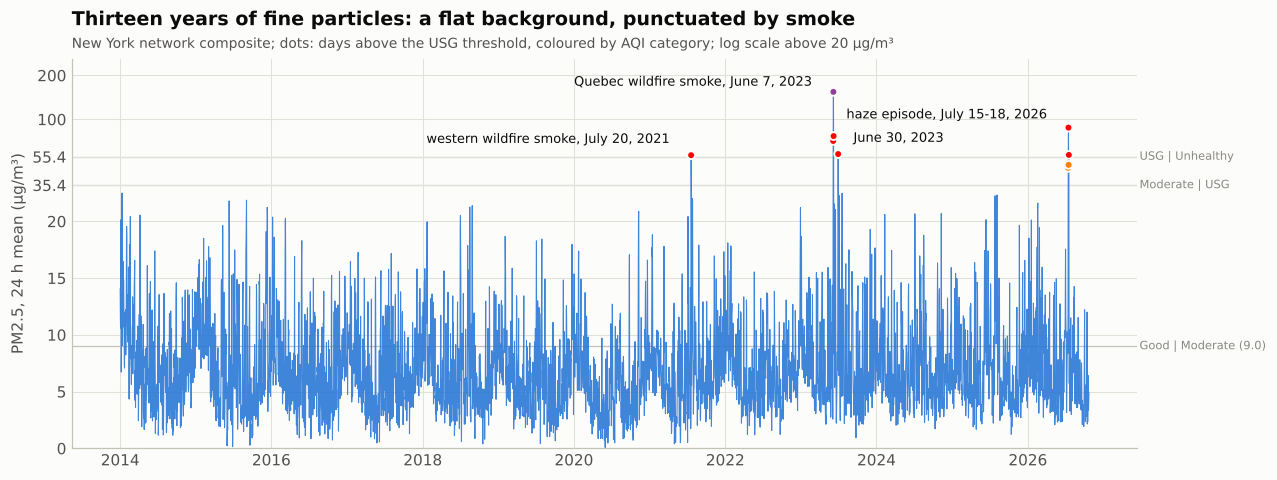

In [16]:
top = nyc_v2.nlargest(10, "pm25")[["pm25", "aqi", "category", "dominant"]].copy()
top["haze reported"] = wx.wt_haze_any.reindex(top.index).map({1.0: "yes", 0.0: "no"})
display(top.round(1))

events = {"2023-06-07": ("Quebec wildfire smoke, June 7, 2023", (-14, 2)),
          "2026-07-16": ("haze episode, July 15-18, 2026", (-14, 4)),
          "2021-07-20": ("western wildfire smoke, July 20, 2021", (-14, 6)),
          "2023-06-30": ("June 30, 2023", (10, 6))}
fig, ax = plt.subplots(figsize=(12.5, 4.6))
s = nyc_v2.pm25
ax.plot(s.index, s, color=viz.POLLUTANT_COLORS["pm25"], lw=0.7, alpha=0.9)
hi_days = s[s > 35.4]
ax.scatter(hi_days.index, hi_days, s=26, c=viz.aqi_color(ix.epa_subindex(hi_days, "pm25")), edgecolor=viz.SURFACE,
           lw=1.2, zorder=3)
ax.set_yscale("symlog", linthresh=20, linscale=1.4)
ax.set_yticks([0, 5, 10, 15, 20, 35.4, 55.4, 100, 200], ["0", "5", "10", "15", "20", "35.4", "55.4", "100", "200"])
ax.minorticks_off()
for thr, lab in [(9.0, "Good | Moderate (9.0)"), (35.4, "Moderate | USG"), (55.4, "USG | Unhealthy")]:
    ax.axhline(thr, color=viz.AXIS, lw=0.8, zorder=0)
    ax.text(1.002, thr, lab, transform=ax.get_yaxis_transform(), fontsize=7.5, color=viz.MUTED, va="center")
for day, (lab, off) in events.items():
    dt = pd.Timestamp(day)
    ax.annotate(lab, xy=(dt, s[dt]), xytext=off, textcoords="offset points", ha="right" if off[0] < 0 else "left",
                va="bottom", fontsize=8.5, color=viz.INK)
ax.set_ylim(0, 260)
ax.set_ylabel("PM2.5, 24 h mean (µg/m³)")
viz.title(ax, "Thirteen years of fine particles: a flat background, punctuated by smoke",
          "New York network composite; dots: days above the USG threshold, coloured by AQI category; "
          "log scale above 20 µg/m³")
viz.save(fig, "01_events_timeline")
plt.show()

### 6.2 · Fireworks

Superposed epoch analysis: for each year, PM2.5 around July 4 and January 1 minus a
baseline (median of days -15 to -5 and +5 to +15). The **median across years** is used
so that a single smoke episode (June 30, 2023 falls 4 days before July 4) cannot fake a
signal. Shaded: 90% bootstrap interval of that median.

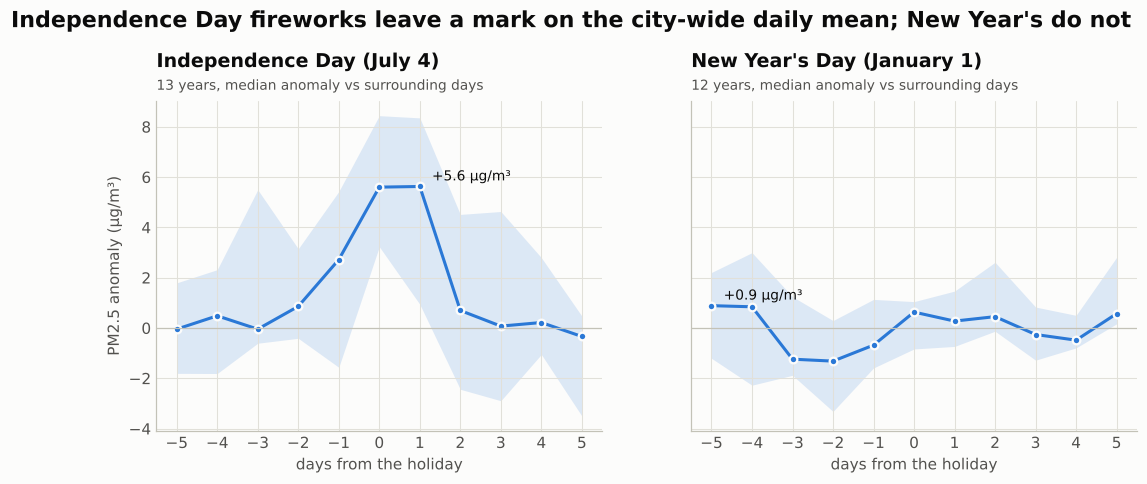

,holiday,years,day 0,day +1,peak 90% CI
0,Independence Day (July 4),13,5.60,5.63,"[0.9, 8.4]"
1,New Year's Day (January 1),12,0.63,0.27,"[-1.2, 2.2]"


In [17]:
def epoch(series, month, day, half=5):
    rows = {}
    for y in range(2014, LAST_DAY.year + 1):
        c = pd.Timestamp(year=y, month=month, day=day)
        if c + pd.Timedelta(days=15) > LAST_DAY or c - pd.Timedelta(days=15) < series.index[0]:
            continue
        win = series.loc[c - pd.Timedelta(days=15):c + pd.Timedelta(days=15)]
        off = (win.index - c).days
        rows[y] = pd.Series(win.to_numpy() - win[np.abs(off) >= 5].median(), index=off).loc[-half:half]
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
fw_rows = []
for ax, (m_, d_, name) in zip(axes, [(7, 4, "Independence Day (July 4)"), (1, 1, "New Year's Day (January 1)")]):
    E = epoch(nyc_v2.pm25, m_, d_)
    med = E.median(axis=1)
    boots = np.array([E.iloc[:, RNG.integers(0, E.shape[1], E.shape[1])].median(axis=1) for _ in range(2000)])
    lo, hi = np.percentile(boots, [5, 95], axis=0)
    ax.fill_between(med.index, lo, hi, color=viz.POLLUTANT_COLORS["pm25"], alpha=0.15, lw=0)
    ax.plot(med.index, med, color=viz.POLLUTANT_COLORS["pm25"], marker="o", ms=5,
            markeredgecolor=viz.SURFACE, markeredgewidth=1.5)
    peak = med.idxmax()
    ax.annotate(f"{med.max():+.1f} µg/m³", xy=(peak, med.max()), xytext=(8, 4), textcoords="offset points",
                fontsize=9, color=viz.INK)
    ax.axhline(0, color=viz.AXIS, lw=0.8)
    ax.set_xticks(range(-5, 6))
    ax.set_xlabel("days from the holiday")
    viz.title(ax, name, f"{E.shape[1]} years, median anomaly vs surrounding days")
    fw_rows.append({"holiday": name, "years": E.shape[1], "day 0": med.loc[0], "day +1": med.loc[1],
                    "peak 90% CI": f"[{lo[med.index.get_loc(peak)]:.1f}, {hi[med.index.get_loc(peak)]:.1f}]"})
axes[0].set_ylabel("PM2.5 anomaly (µg/m³)")
viz.fig_title(fig, "Independence Day fireworks leave a mark on the city-wide daily mean; New Year's do not")
viz.save(fig, "01_fireworks")
plt.show()
display(pd.DataFrame(fw_rows).round(2))

### 6.3 · The COVID-19 lockdown, against a business-as-usual counterfactual

New York's "PAUSE" order took effect on March 22, 2020. A model trained on all other
years (weather, season, weekday, holidays and a smooth time trend; the period March 2020
to June 2021 excluded) predicts what NO2 and PM2.5 *would have been* from March 15 to
June 30, 2020. The gap between observation and counterfactual is the lockdown effect,
summarised by the median daily ratio (robust to smoke episodes) with a weekly block
bootstrap.

**In-time placebo test.** The whole procedure is rerun on the same window of every other
year, where the true effect is zero. The spread of these placebo "effects" is the noise
floor of the method: a lockdown estimate is only credible if it stands outside it.

In [18]:
WX_CF = ["t_mean", "t_max", "t_min", "td_mean", "rh_mean", "slp_mean", "ws_mean", "u_mean", "v_mean",
         "calm_frac", "prcp", "snwd", "t_aft", "ws_aft"]
cf_base = nyc_v2[["no2", "pm25"]].join(wx[WX_CF]).join(
    features.calendar_features(nyc_v2.index)[["doy_sin", "doy_cos", "dow", "holiday", "year_frac"]])


def counterfactual(target: str, year: int, start="03-15", end="06-30", exclude=("2020-03-01", "2021-06-30"),
                   min_days: int = 60):
    df = cf_base.drop(columns=[c for c in ("no2", "pm25") if c != target]).dropna(subset=[target] + WX_CF)
    test = df.loc[f"{year}-{start}":f"{year}-{end}"]
    if len(test) < min_days:
        return None
    train = df.drop(test.index)
    train = train[~((train.index >= exclude[0]) & (train.index <= exclude[1]))]
    feats = [c for c in df.columns if c != target]
    preds = [lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, random_state=seed, verbose=-1, n_jobs=4)
             .fit(train[feats], train[target]).predict(test[feats]) for seed in range(3)]
    out = pd.DataFrame({"obs": test[target], "bau": np.mean(preds, axis=0)})
    # robust effect: median daily log ratio, so that one smoke episode cannot dominate;
    # uncertainty from a block bootstrap over weeks
    lr = np.log(np.clip(out.obs, 0.5, None) / np.clip(out.bau, 0.5, None))
    eff = 100 * (np.exp(lr.median()) - 1)
    weeks = [g.to_numpy() for _, g in lr.groupby(lr.index.to_period("W"))]
    boots = [100 * (np.exp(np.median(np.concatenate([weeks[i] for i in RNG.integers(0, len(weeks), len(weeks))])))
                    - 1) for _ in range(2000)]
    return out, eff, np.percentile(boots, [5, 95])


cf_rows, cf_series = [], {}
for target in ["no2", "pm25"]:
    for year in range(2014, 2026):
        if year == 2021:
            continue
        res = counterfactual(target, year)
        if res is None:
            continue
        out, eff, ci = res
        cf_series[(target, year)] = out
        cf_rows.append({"pollutant": target, "year": year, "role": "lockdown" if year == 2020 else "placebo",
                        "effect (%)": eff, "ci_lo": ci[0], "ci_hi": ci[1], "days": len(out)})
cf = pd.DataFrame(cf_rows)
summary = []
for target in ["no2", "pm25"]:
    c = cf[cf.pollutant == target]
    lock, plc = c[c.role == "lockdown"].iloc[0], c[c.role == "placebo"]
    summary.append({"pollutant": target, "lockdown effect (%)": lock["effect (%)"],
                    "90% CI": f"[{lock.ci_lo:.1f}, {lock.ci_hi:.1f}]", "placebo years": len(plc),
                    "placebo mean (%)": plc["effect (%)"].mean(), "placebo sd (%)": plc["effect (%)"].std(),
                    "placebo years with a larger drop": int((plc["effect (%)"] <= lock["effect (%)"]).sum())})
display(pd.DataFrame(summary).round(1))

,pollutant,lockdown effect (%),90% CI,placebo years,placebo mean (%),placebo sd (%),placebo years with a larger drop
0,no2,-15.2,"[-19.0, -12.3]",5,-1.7,3.2,0
1,pm25,-39.4,"[-46.4, -34.7]",10,-5.4,8.2,0


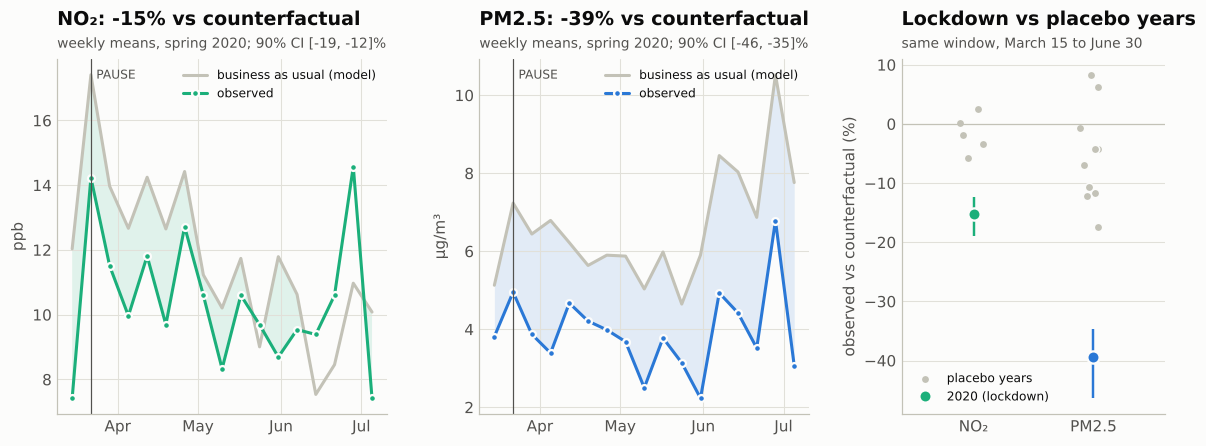

In [19]:
fig = plt.figure(figsize=(13, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.8], wspace=0.3)
for k, (target, unit) in enumerate([("no2", "ppb"), ("pm25", "µg/m³")]):
    ax = fig.add_subplot(gs[k])
    out = cf_series[(target, 2020)].resample("W").mean()
    color = viz.POLLUTANT_COLORS[target]
    ax.plot(out.index, out.bau, color=viz.CONTEXT, lw=2, label="business as usual (model)")
    ax.plot(out.index, out.obs, color=color, lw=2, marker="o", ms=4.5, markeredgecolor=viz.SURFACE,
            markeredgewidth=1.5, label="observed")
    ax.fill_between(out.index, out.obs, out.bau, where=out.obs < out.bau, color=color, alpha=0.12, lw=0,
                    interpolate=True)
    ax.axvline(pd.Timestamp("2020-03-22"), color=viz.INK_2, lw=0.8)
    ax.text(pd.Timestamp("2020-03-24"), 0.97, "PAUSE", transform=ax.get_xaxis_transform(), fontsize=8,
            color=viz.INK_2, va="top")
    row = cf[(cf.pollutant == target) & (cf.role == "lockdown")].iloc[0]
    viz.title(ax, f"{viz.POLLUTANT_LABELS[target]}: {row['effect (%)']:+.0f}% vs counterfactual",
              f"weekly means, spring 2020; 90% CI [{row.ci_lo:.0f}, {row.ci_hi:.0f}]%")
    ax.set_ylabel(unit)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.legend(loc="upper right", fontsize=8)
ax = fig.add_subplot(gs[2])
for k, target in enumerate(["no2", "pm25"]):
    c = cf[cf.pollutant == target]
    plc, lock = c[c.role == "placebo"], c[c.role == "lockdown"].iloc[0]
    jitter = RNG.uniform(-0.12, 0.12, len(plc))
    ax.scatter(k + jitter, plc["effect (%)"], s=30, color=viz.CONTEXT, edgecolor=viz.SURFACE, lw=1, zorder=2,
               label="placebo years" if k == 0 else None)
    ax.errorbar(k, lock["effect (%)"], yerr=[[lock["effect (%)"] - lock.ci_lo], [lock.ci_hi - lock["effect (%)"]]],
                fmt="o", ms=8, color=viz.POLLUTANT_COLORS[target], mec=viz.SURFACE, mew=1.5, lw=1.6, zorder=3,
                label="2020 (lockdown)" if k == 0 else None)
ax.axhline(0, color=viz.AXIS, lw=0.8)
ax.set_xticks([0, 1], ["NO₂", "PM2.5"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("observed vs counterfactual (%)")
viz.title(ax, "Lockdown vs placebo years", "same window, March 15 to June 30")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="x", visible=False)
viz.save(fig, "01_covid_counterfactual")
plt.show()

## 7 · Forecasting the next three days

**Targets:** the network composites of PM2.5 and ozone, from which the AQI follows.
**Model:** gradient boosting with quantile losses (median and 10%/90% quantiles), then
**conformalised quantile regression** (CQR): the band is rescaled on the most recent
20% of the training data so that the 80% interval really covers about 80% of outcomes.

**Features** at issue time *t*: the last 7 days of both pollutants, 7/14/28-day rolling
statistics, today's weather, the calendar of the target day, and two settings for the
weather of the target day:

* *operational*: no information about tomorrow's weather;
* *with weather forecast*: the observed weather of the target day stands in for a
  perfect weather forecast, which bounds the value a weather forecast can add.

**Protocol:** walk-forward, six folds. Each test year (2021 to 2026) is predicted by a
model trained only on earlier years. Baselines: persistence (tomorrow = today) and a
day-of-year climatology.

In [20]:
WX_FC = ["tmax", "tmin", "prcp", "awnd", "wsf2", "gust_u", "gust_v", "snwd"]
panel = nyc_v2[["pm25", "o3"]].join(wx[WX_FC]).asfreq("D")
HORIZONS = [1, 2, 3]
FOLDS = [(f"{y}-01-01", f"{y}-12-31") for y in range(2021, LAST_DAY.year + 1)]


def dataset(target: str, h: int, weather_forecast: bool):
    y = panel[target].rename(target)
    other = "o3" if target == "pm25" else "pm25"
    past = pd.concat([features.lag_features(panel[other], range(0, 3), other), panel[WX_FC]], axis=1)
    return features.make_direct_dataset(y, h, lags=range(0, 7), windows=[7, 14, 28], exog_past=past,
                                        exog_future=panel[WX_FC] if weather_forecast else None)


results, preds_store = [], {}
for target in ["pm25", "o3"]:
    for setting in ["operational", "with weather forecast"]:
        for h in HORIZONS:
            X, t = dataset(target, h, setting != "operational")
            p = fc.walk_forward(X, t, FOLDS, lambda: fc.QuantileBooster(alpha=0.2, params={"n_estimators": 400}))
            yv = panel[target]
            p["persistence"] = yv.shift(h).reindex(p.index).to_numpy()
            p["climatology"] = np.concatenate([fc.climatology(yv, pd.Timestamp(f) - pd.Timedelta(days=1))
                                               .reindex(p.index[p.fold == f]).to_numpy() for f in p.fold.unique()])
            preds_store[(target, setting, h)] = p
            m, mp, mc = (fc.regression_scores(p.y, p[c]) for c in ("median", "persistence", "climatology"))
            iv, ivr = fc.interval_scores(p.y, p.lo, p.hi, 0.2), fc.interval_scores(p.y, p.lo_raw, p.hi_raw, 0.2)
            results.append({"target": target, "setting": setting, "h": h, "MAE": m["MAE"], "RMSE": m["RMSE"],
                            "R2": m["R2"], "MAE persistence": mp["MAE"], "MAE climatology": mc["MAE"],
                            "skill vs persistence": fc.skill(m["MAE"], mp["MAE"]),
                            "skill vs climatology": fc.skill(m["MAE"], mc["MAE"]),
                            "coverage 80% (CQR)": iv["coverage"], "coverage 80% (raw)": ivr["coverage"],
                            "width": iv["width"]})
scores = pd.DataFrame(results)
display(scores.round(3))

,target,setting,h,MAE,RMSE,R2,MAE persistence,MAE climatology,skill vs persistence,skill vs climatology,coverage 80% (CQR),coverage 80% (raw),width
0,pm25,operational,1,2.411,5.583,0.192,2.877,3.062,0.162,0.212,0.814,0.708,7.057
1,pm25,operational,2,2.979,6.180,0.010,3.955,3.062,0.247,0.027,0.808,0.687,8.349
2,pm25,operational,3,3.010,6.199,0.004,4.333,3.062,0.305,0.017,0.811,0.688,8.604
3,pm25,with weather forecast,1,1.972,5.335,0.262,2.877,3.062,0.314,0.356,0.813,0.705,5.935
4,pm25,with weather forecast,2,2.253,5.735,0.147,3.955,3.062,0.430,0.264,0.814,0.688,6.430
5,pm25,with weather forecast,3,2.313,5.786,0.132,4.333,3.062,0.466,0.244,0.808,0.677,6.341
6,o3,operational,1,6.294,8.131,0.585,7.641,7.122,0.176,0.116,0.814,0.688,20.741
7,o3,operational,2,7.012,9.156,0.474,9.317,7.122,0.247,0.015,0.811,0.682,23.030
8,o3,operational,3,7.204,9.427,0.442,9.734,7.122,0.260,-0.011,0.812,0.688,23.439
9,o3,with weather forecast,1,4.419,5.783,0.790,7.641,7.122,0.422,0.380,0.818,0.683,16.282


From pollutant forecasts to **AQI category forecasts**: accuracy, and the detection of
days above AQI 100 ("Unhealthy for Sensitive Groups"). A median forecast almost never
crosses a rare threshold, so the alert rule uses the **upper bound of the 80% interval**:
warn when it exceeds 100.

In [21]:
def aqi_from(pm, o3):
    return np.fmax(ix.epa_subindex(pm, "pm25"), ix.epa_subindex(o3, "o3_8h"))


cat_rows = []
for setting in ["operational", "with weather forecast"]:
    for h in HORIZONS:
        pp, po = preds_store[("pm25", setting, h)], preds_store[("o3", setting, h)]
        j = pp.index.intersection(po.index)
        obs = aqi_from(pp.y[j], po.y[j])
        ok_ = ~np.isnan(obs)
        fcst = aqi_from(pp["median"][j], po["median"][j])
        upper = aqi_from(pp.hi[j], po.hi[j])
        pers = aqi_from(pp.persistence[j], po.persistence[j])
        warn, pers_ex = fc.exceedance_scores(obs, upper, 100), fc.exceedance_scores(obs, pers, 100)
        cat_rows.append({"setting": setting, "h": h,
                         "category accuracy": np.mean(ix.epa_category(obs[ok_]) == ix.epa_category(fcst[ok_])),
                         "accuracy persistence": np.mean(ix.epa_category(obs[ok_]) == ix.epa_category(pers[ok_])),
                         "AQI>100 days": warn["events"], "POD (alert rule)": warn["POD"],
                         "FAR (alert rule)": warn["FAR"], "POD persistence": pers_ex["POD"],
                         "FAR persistence": pers_ex["FAR"]})
display(pd.DataFrame(cat_rows).round(3))

,setting,h,category accuracy,accuracy persistence,AQI>100 days,POD (alert rule),FAR (alert rule),POD persistence,FAR persistence
0,operational,1,0.772,0.735,32,0.250,0.652,0.281,0.719
1,operational,2,0.712,0.642,32,0.000,NaN,0.125,0.875
2,operational,3,0.717,0.613,32,0.000,1.000,0.031,0.969
3,with weather forecast,1,0.832,0.735,32,0.281,0.690,0.281,0.719
4,with weather forecast,2,0.809,0.642,32,0.281,0.700,0.125,0.875
5,with weather forecast,3,0.798,0.613,32,0.219,0.696,0.031,0.969


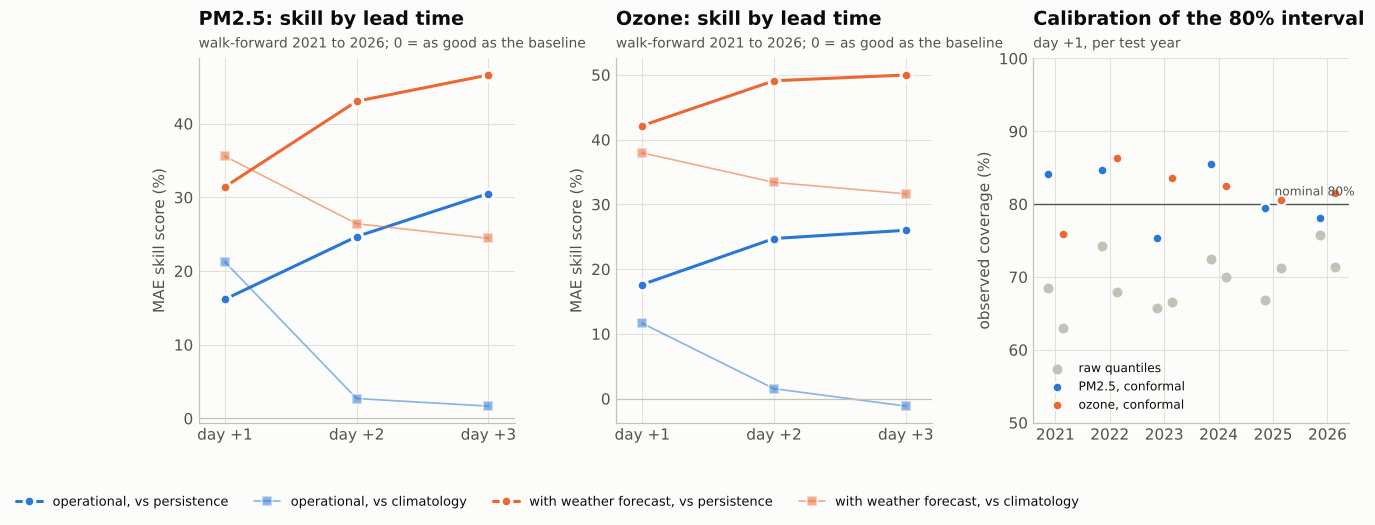

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), gridspec_kw={"wspace": 0.32})
styles = {"operational": viz.SERIES[0], "with weather forecast": viz.SERIES[1]}
for ax, target in zip(axes[:2], ["pm25", "o3"]):
    for setting, color in styles.items():
        sc = scores[(scores.target == target) & (scores.setting == setting)]
        ax.plot(sc.h, 100 * sc["skill vs persistence"], color=color, marker="o", ms=7, markeredgecolor=viz.SURFACE,
                markeredgewidth=2, label=f"{setting}, vs persistence")
        ax.plot(sc.h, 100 * sc["skill vs climatology"], color=color, marker="s", ms=6, lw=1.1, alpha=0.55,
                markeredgecolor=viz.SURFACE, markeredgewidth=1.5, label=f"{setting}, vs climatology")
    ax.axhline(0, color=viz.AXIS, lw=0.8)
    ax.set_xticks(HORIZONS, [f"day +{h}" for h in HORIZONS])
    ax.set_xlim(0.8, 3.2)
    ax.set_ylabel("MAE skill score (%)")
    viz.title(ax, ("PM2.5" if target == "pm25" else "Ozone") + ": skill by lead time",
              "walk-forward 2021 to 2026; 0 = as good as the baseline")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.36, -0.02), fontsize=8.5)
ax = axes[2]
for k, target in enumerate(["pm25", "o3"]):
    p = preds_store[(target, "with weather forecast", 1)]
    cov = p.groupby("fold").apply(lambda g: np.mean((g.y >= g.lo) & (g.y <= g.hi)))
    cov_raw = p.groupby("fold").apply(lambda g: np.mean((g.y >= g.lo_raw) & (g.y <= g.hi_raw)))
    xs = np.arange(len(cov)) + (k - 0.5) * 0.28
    ax.scatter(xs, 100 * cov_raw, s=30, color=viz.CONTEXT, zorder=2, label="raw quantiles" if k == 0 else None)
    ax.scatter(xs, 100 * cov, s=42, color=viz.POLLUTANT_COLORS[target], edgecolor=viz.SURFACE, lw=1.5, zorder=3,
               label=("PM2.5" if target == "pm25" else "ozone") + ", conformal")
ax.axhline(80, color=viz.INK_2, lw=0.9)
ax.text(len(cov) - 0.5, 81.2, "nominal 80%", fontsize=8, color=viz.INK_2, ha="right")
ax.set_xticks(range(len(cov)), [f[:4] for f in cov.index])
ax.set_ylim(50, 100)
ax.set_ylabel("observed coverage (%)")
viz.title(ax, "Calibration of the 80% interval", "day +1, per test year")
ax.legend(loc="lower left", fontsize=8)
viz.save(fig, "01_forecast_skill")
plt.show()

### 7.1 · What drives tomorrow's air? Exact TreeSHAP contributions

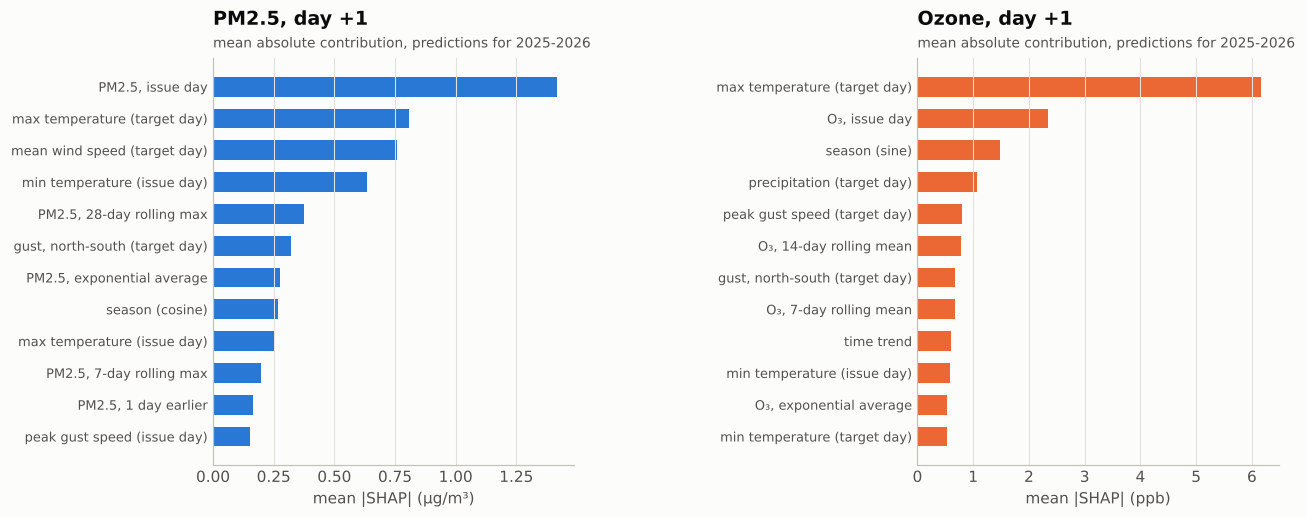

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"wspace": 0.95})
for ax, target in zip(axes, ["pm25", "o3"]):
    X, t = dataset(target, 1, True)
    tr = t.notna() & (X.index < "2025-01-01")
    model = fc.QuantileBooster(alpha=0.2, params={"n_estimators": 400}).fit(X[tr], t[tr])
    sv = model.shap_values(X[(X.index >= "2025-01-01") & t.notna()]).drop(columns="expected_value")
    imp = sv.abs().mean().sort_values().tail(12)
    ax.barh(range(len(imp)), imp, height=0.62, color=viz.POLLUTANT_COLORS[target])
    ax.set_yticks(range(len(imp)), [viz.pretty_feature(c) for c in imp.index], fontsize=8.5)
    ax.set_xlabel("mean |SHAP| (" + ("µg/m³" if target == "pm25" else "ppb") + ")")
    viz.title(ax, ("PM2.5" if target == "pm25" else "Ozone") + ", day +1",
              "mean absolute contribution, predictions for 2025-2026")
    ax.grid(axis="y", visible=False)
viz.save(fig, "01_forecast_shap")
plt.show()

Yesterday's level dominates PM2.5, while tomorrow's maximum temperature dominates ozone:
photochemistry needs heat and sunlight, which is why a weather forecast adds far more
skill for ozone than for particles.

### 7.2 · Live forecast

Trained on every day up to the last complete AirNow day, in the operational setting (no
knowledge of future weather; the GHCN feed itself lags by a few days).

In [24]:
live = []
for target in ["pm25", "o3"]:
    for h in HORIZONS:
        X, t = dataset(target, h, False)
        tr = t.notna()
        model = fc.QuantileBooster(alpha=0.2, params={"n_estimators": 400}).fit(X[tr], t[tr])
        Xl = X.loc[[LAST_DAY + pd.Timedelta(days=h)]]
        p = model.predict(Xl)
        live.append({"date": Xl.index[0], "target": target, "median": p["median"].iloc[0], "lo": p.lo.iloc[0],
                     "hi": p.hi.iloc[0]})
live = pd.DataFrame(live).pivot(index="date", columns="target")
live_aqi = pd.DataFrame({
    "PM2.5 (ug/m3)": live[("median", "pm25")].round(1),
    "PM2.5 80% interval": [f"{a:.1f} to {b:.1f}" for a, b in zip(live[("lo", "pm25")], live[("hi", "pm25")])],
    "O3 (ppb)": live[("median", "o3")].round(0),
    "O3 80% interval": [f"{a:.0f} to {b:.0f}" for a, b in zip(live[("lo", "o3")], live[("hi", "o3")])],
})
live_aqi["AQI"] = aqi_from(live[("median", "pm25")], live[("median", "o3")])
live_aqi["AQI upper (80%)"] = aqi_from(live[("hi", "pm25")], live[("hi", "o3")])
live_aqi["category"] = ix.epa_category_name(live_aqi.AQI)
print(f"forecast issued from data up to {LAST_DAY:%Y-%m-%d}")
display(live_aqi)
live_aqi.to_csv(out_dir / "nyc_live_forecast.csv")

forecast issued from data up to 2026-10-23


,PM2.5 (ug/m3),PM2.5 80% interval,O3 (ppb),O3 80% interval,AQI,AQI upper (80%),category
date,,,,,,,
2026-10-24,4.9,4.0 to 7.9,31.0,24 to 37,29.0,43.0,Good
2026-10-25,4.9,3.5 to 8.2,29.0,23 to 40,27.0,45.0,Good
2026-10-26,6.5,3.6 to 12.5,30.0,22 to 39,36.0,57.0,Good


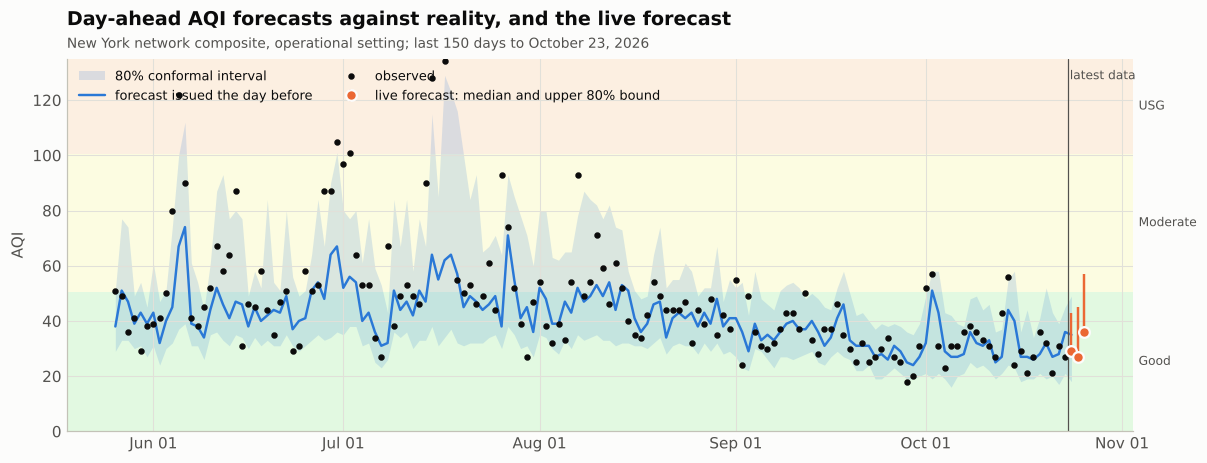

In [25]:
fig, ax = plt.subplots(figsize=(12.5, 4.4))
seg_start = LAST_DAY - pd.Timedelta(days=150)
p1 = {t_: preds_store[(t_, "operational", 1)] for t_ in ["pm25", "o3"]}
j = p1["pm25"].index.intersection(p1["o3"].index)
j = j[j >= seg_start]
obs_aqi = aqi_from(p1["pm25"].y[j], p1["o3"].y[j])
med_aqi = aqi_from(p1["pm25"]["median"][j], p1["o3"]["median"][j])
lo_aqi = aqi_from(p1["pm25"].lo[j], p1["o3"].lo[j])
hi_aqi = aqi_from(p1["pm25"].hi[j], p1["o3"].hi[j])
ax.fill_between(j, lo_aqi, hi_aqi, color=viz.SERIES[0], alpha=0.16, lw=0, label="80% conformal interval")
ax.plot(j, med_aqi, color=viz.SERIES[0], lw=1.6, label="forecast issued the day before")
ax.plot(j, obs_aqi, color=viz.INK, lw=0, marker="o", ms=3.2, label="observed")
lf = live_aqi.index
ax.errorbar(lf, live_aqi.AQI, yerr=[np.zeros(len(lf)), live_aqi["AQI upper (80%)"] - live_aqi.AQI],
            fmt="o", color=viz.SERIES[1], ms=7, mec=viz.SURFACE, mew=1.5, capsize=0, lw=1.6,
            label="live forecast: median and upper 80% bound")
ax.axvline(LAST_DAY + pd.Timedelta(hours=12), color=viz.INK_2, lw=0.8)
ax.text(LAST_DAY + pd.Timedelta(hours=18), 0.97, "latest data", transform=ax.get_xaxis_transform(), fontsize=8,
        color=viz.INK_2, va="top")
viz.aqi_bands(ax, ymax=135, alpha=0.10)
ax.set_ylabel("AQI")
viz.title(ax, "Day-ahead AQI forecasts against reality, and the live forecast",
          f"New York network composite, operational setting; last 150 days to {LAST_DAY:%B %d, %Y}")
ax.legend(loc="upper left", ncol=2, fontsize=8.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
viz.save(fig, "01_forecast_live")
plt.show()

## 8 · Take-aways

* The v1 export was read on the wrong scale and contained two silent sensor failures.
  After QC it agrees with the regulatory network, and the v1 headline "2021 was the
  worst year" disappears: it was a drifting sensor.
* The `aqi2` engine reproduces AirNow's published AQI (exactly for ozone, within one
  point for PM2.5) and makes the 2024 PM2.5 revision visible: the same air is "Moderate"
  far more often under the new rules, and far more often still under WHO benchmarks.
* Weather-normalised trends separate emissions from meteorology: PM2.5 has plateaued
  around 7 ug/m3 since 2014 while ozone rises by under 1% per year. The lockdown
  estimates (NO2 and PM2.5 both well below their counterfactual) come with an in-time
  placebo test, so their size can be judged against the method's own noise.
* Day-ahead forecasts beat persistence and climatology, and conformal calibration turns
  quantile bands into intervals with honest coverage. Smoke onsets remain the hardest
  days to forecast from local data alone: a smoke transport forecast would be the next
  input.

## 9 · Key results

Saved to `data/processed/results_01.json`, from which `scripts/make_report.py` fills
the numbers of the report.

In [26]:
import json  # noqa: E402


def r(x, n=2):
    return round(float(x), n)


chk = pd.DataFrame(checks).set_index("breakpoints")
sc1 = scores[scores.h == 1].set_index(["target", "setting"])
cat1 = pd.DataFrame(cat_rows).set_index(["setting", "h"])
cfs = pd.DataFrame(summary).set_index("pollutant")
who_year = who / n_days * 365
res01 = {
    "nyc_pm_monitors": int(pm_st.shape[1]), "nyc_o3_monitors": int(o3_st.shape[1]),
    "val_oz_n": int(chk.loc["o3_8h", "station-days"]), "val_oz_exact": r(chk.loc["o3_8h", "exact match (%)"]),
    "val_pm_within": r(min(chk.loc["pm25_2012", "within 1 point (%)"], chk.loc["pm25", "within 1 point (%)"])),
    "v1_good": r(share.loc["Good", "v1 (misread)"], 1), "v2_good": r(share.loc["Good", "v2 (correct)"], 1),
    "flag_oz": int(flag_o3.sum()), "flag_pm": int(flag_pm.sum()), "stable_ratio": r(np.exp(baseline)),
    "corr_before": r(r_before), "corr_after": r(r_after),
    "fill_r2_pm": r(cv_pm["linear + boosting"]["R2"]), "fill_r2_oz": r(cv_o3["linear + boosting"]["R2"]),
    "share_good_2012": r(100 * shares["EPA AQI, 2012 breakpoints"][0].get(0, 0), 0),
    "share_good_2024": r(100 * shares["EPA AQI, 2024 breakpoints"][0].get(0, 0), 0),
    "share_good_eea": r(100 * shares["European EAQI (EEA)"][0].get(0, 0), 0),
    "who_min": int(round(who_year.min())), "who_max": int(round(who_year.max())),
    "trend_pm": r(trends.query("pollutant == 'pm25' and series == 'weather-normalised'")["slope per year"].iloc[0]),
    "trend_oz": r(trends.query("pollutant == 'o3' and series == 'weather-normalised'")["slope per year"].iloc[0]),
    "trend_oz_pct": r(trends.query("pollutant == 'o3' and series == 'weather-normalised'")["% per year"].iloc[0], 1),
    "trend_oz_p": r(trends.query("pollutant == 'o3' and series == 'weather-normalised'")["Mann-Kendall p"].iloc[0], 4),
    "worst_pm": r(top.pm25.iloc[0], 0), "worst_aqi": int(top.aqi.iloc[0]),
    "second_aqi": int(nyc_v2.loc["2026-07-15":"2026-07-18", "aqi"].max()),
    "fireworks_pm": r(fw_rows[0]["day 0"], 1),
    "covid_no2": r(cfs.loc["no2", "lockdown effect (%)"], 0), "covid_pm": r(cfs.loc["pm25", "lockdown effect (%)"], 0),
    "placebo_no2_min": r(cf.query("pollutant == 'no2' and role == 'placebo'")["effect (%)"].min(), 0),
    "placebo_no2_max": r(cf.query("pollutant == 'no2' and role == 'placebo'")["effect (%)"].max(), 0),
    "placebo_pm_min": r(cf.query("pollutant == 'pm25' and role == 'placebo'")["effect (%)"].min(), 0),
    "placebo_pm_max": r(cf.query("pollutant == 'pm25' and role == 'placebo'")["effect (%)"].max(), 0),
    "raw_cov": r(100 * sc1["coverage 80% (raw)"].mean(), 0),
    "cat_acc": r(100 * cat1.loc[("with weather forecast", 1), "category accuracy"], 0),
    "cat_acc_op": r(100 * cat1.loc[("operational", 1), "category accuracy"], 0),
    "cat_acc_pers": r(100 * cat1.loc[("operational", 1), "accuracy persistence"], 0),
    "live_date": f"{live_aqi.index[0]:%Y-%m-%d}", "live_aqi": int(live_aqi.AQI.iloc[0]),
    "live_cat": str(live_aqi.category.iloc[0]), "last_day": f"{LAST_DAY:%Y-%m-%d}",
}
for (target, setting), row in sc1.iterrows():
    key = f"fc_{target}_{'wx' if setting != 'operational' else 'op'}"
    res01[key] = {"mae": r(row.MAE), "skill_pers": r(100 * row["skill vs persistence"], 0),
                  "skill_clim": r(100 * row["skill vs climatology"], 0), "cov": r(100 * row["coverage 80% (CQR)"], 0)}
(data.DATA / "processed" / "results_01.json").write_text(json.dumps(res01, indent=1))
display(pd.Series({k: v for k, v in res01.items() if not isinstance(v, dict)}))

nyc_pm_monitors            14
nyc_o3_monitors             6
val_oz_n               159138
val_oz_exact            100.0
val_pm_within           99.95
v1_good                   1.0
v2_good                  78.0
flag_oz                   157
flag_pm                   174
stable_ratio             1.42
corr_before              0.69
corr_after               0.93
fill_r2_pm               0.94
fill_r2_oz               0.97
share_good_2012          83.0
share_good_2024          72.0
share_good_eea           14.0
who_min                     7
who_max                    33
trend_pm                 0.01
trend_oz                 0.25
trend_oz_pct              0.7
trend_oz_p                0.0
worst_pm                154.0
worst_aqi                 229
second_aqi                174
fireworks_pm              5.6
covid_no2               -15.0
covid_pm                -39.0
placebo_no2_min          -6.0
placebo_no2_max           3.0
placebo_pm_min          -17.0
placebo_pm_max            8.0
raw_cov   